---

# Data Science Competition FIK FAIR 2026

*Predicting an Anonymous Competition Score from 24 transformed environmental and climate features (version 9, row-order information combined with the version 8 feature models).*

---

## Team Name

- Name 1 (Role)
- Name 2
- Name 3

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Exploratory Data Analysis**](#3)
4. [**Deep Analysis of the Data Generating Process**](#4)
5. [**Preprocessing Verification**](#5)
6. [**Modelling**](#6)
7. [**Ensemble, Selection Protocol and Limits**](#7)
8. [**Row-Order Information**](#8)
9. [**Submission**](#9)


---

# Introduction <a name="1"></a>

---

## Overview

*FIK FAIR 2026 hosts a tabular regression competition in which each record is described by 24 anonymised numerical features derived from environmental and climate indicators. The organisers passed the raw indicators through rank normalisation, a bounded transformation, a private linear projection, standardisation, controlled perturbation and rounding, so the features carry no physical unit and no known meaning.*

*The target is the Anonymous Competition Score, a constructed composite whose formula is private. With only 382 labelled rows, the main risks are overfitting, optimistic validation and chasing a public leaderboard that is computed on roughly 29 rows.*

*This is the second version of the solution. Version 1 (TabICLv2 blended with a kernel SVR) scored 7.947 on the public leaderboard against a nested cross-validation estimate of 7.41, a gap that is well inside the sampling noise of 29 public rows. Version 2 re-examines the data generating process in depth, tests every new idea against the same folds, and changes the model only where the cross-validated evidence is consistent.*

*Version 2 scored 7.902 on the public leaderboard (version 1: 7.947), moving in the direction its cross-validation predicted. Version 3 tests four more ideas (alternative feature bases, test-time jitter, a correctly back-transformed log target and transductive pseudo-labelling). Only pseudo-labelling survives validation, and the analysis links it to the sample-density limit found in version 2.*

*Version 9 adds a finding that every earlier version missed: the rows of the provided files are sorted by the target. The organisers confirmed to the team that using the row order is part of each participant's EDA and preprocessing, so the final prediction combines the order of the test file with the version 8 feature models.*

*Version 3 scored 7.888 on the public leaderboard, again in the direction cross-validation predicted. Version 4 keeps the version 3 model unchanged and adds the evidence that its gain is trustworthy: the test set has the same geometry as the random validation folds, the gain does not shrink as labelled data grows, and no further variant beats it by more than the seed noise.*

*Version 5 adds the gated Prior Labs checkpoints (TabPFN 2.5, 2.6, 3 and 3.5). Only TabPFN-3.5 is competitive, and with the same pseudo-labelling it matches TabICLv2. Averaging the two pseudo-labelled foundation models, which come from different pretraining priors, reduces variance beyond what seed bagging of one model achieves.*

*Version 5 tied version 3 on the public leaderboard (7.888). Version 6 searches for blend members whose errors differ from the foundation models. Networks trained from scratch and rough kernels fail, but a less regularised SVR, averaged over a plateau of settings, makes more independent errors and improves the blend.*

## Aim

*The notebook aims to minimise the RMSE of the predicted score on the private leaderboard. Every preprocessing idea is treated as a hypothesis and kept only when repeated cross-validation confirms it, and the final predictor is a cross-validated blend of kernel models, gradient boosting and pretrained tabular foundation models.*

## Metric

***Root Mean Squared Error (RMSE)** measures the typical size of the prediction error in target units, with large errors penalised quadratically. It is the primary ranking metric, and MAE is used as the tie-breaker.*

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2}$$

*Because the loss is quadratic, the few records with a score above 70 dominate the error budget, so the analysis pays special attention to the right tail of the target.*

## Dataset

*Data sourced from Kaggle at: https://www.kaggle.com/competitions/data-science-competition-fikfair2026*

*The dataset contains 478 records, split into 382 training rows with a target and 96 test rows without one. There are no missing values and every feature is stored with six decimals.*

*The dataset is used to learn a mapping from the anonymised features to the Anonymous Competition Score.*

**Attributes**

1.  `record_id`                  : Anonymous technical identifier with no geographic or source meaning
2.  `feature_01` to `feature_24` : Transformed, dimensionless environmental and climate features

**Target**
 `target`       : Anonymous Competition Score, a continuous value between about 32.6 and 100.4

## Approach: Transductive Pseudo-Labelling and a Seed-Bagged Blend

*The approach combines models that see the data in different ways. Kernel models (SVR, kNN) work on a 12-component PCA view of the features with a log-shifted target, gradient boosting works on the raw features, and the pretrained foundation models TabICLv2 and TabPFN v2 predict through in-context learning without any gradient training on the competition data.*

*All models share the same repeated 5-fold split, and the blend weights are fitted with non-negative least squares on out-of-fold predictions, with a nested split to estimate the blend error honestly.*

```
24 raw features
    |
    +-- StandardScaler -> PCA(10..20) -> SVR, C in {10, 30}, two length-scales (target: log(y - 30))
    +-- raw features  -> CatBoost / ExtraTrees  (target: y)
    +-- raw features  -> TabICLv2 (norm=none, 4 seeds) / TabPFN v2 / TabDPT
    +-- raw features  -> TabICLv2 + pseudo-labelled query rows in the context (version 3)
    +-- raw features  -> TabPFN-3.5 + pseudo-labelled query rows in the context (version 5)
         |
    NNLS blend on out-of-fold predictions -> prediction
```

*Version 2 adds three candidates to the pool (TabICLv2 without internal power normalisation, bagged over four random states, the real-data foundation model TabDPT, and a fine-tuned TabICLv2) and a selection protocol that decides between them with nested, multi-seed cross-validation, a paired bootstrap and a leaderboard simulation instead of the public score.*

*Version 3 adds transductive pseudo-labelling. The unlabeled rows being predicted are first labelled by TabICLv2, and then each quarter of them is predicted again with the other three quarters added to the context, so no row ever sees its own pseudo label. This densifies the context around every query, which targets the sample-density limit identified by the variogram.*

*The split is plain repeated K-fold because the test rows are no closer to the training rows than the training rows are to each other, which the neighbour analysis in Section 3 verifies.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

The notebook targets a Kaggle session with two T4 GPUs and internet access enabled, which is needed to install the foundation model packages and download their checkpoints. The TabPFN 2.5, 2.6, 3 and 3.5 checkpoints are gated by Prior Labs: the licence must be accepted once at ux.priorlabs.ai and the API key stored as a Kaggle secret named `TABPFN_TOKEN` (Add-ons, Secrets). Recorded runtime: about 60 minutes on a laptop CPU (Intel Core Ultra 7 155H). On the following two T4 GPUs the foundation models run many times faster (version 1 took under a minute per foundation model on this hardware).

In [1]:
!nvidia-smi

Sun Oct  4 16:42:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook.

In [2]:
%pip install -q tabicl tabpfn tabdpt transformers catboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.4/310.4 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 67.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 28.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [3]:
import os
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy import stats
from scipy.optimize import nnls
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist, pdist
from statsmodels.nonparametric.smoothers_lowess import lowess

from catboost import CatBoostRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA, FastICA
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (GroupKFold, KFold, RepeatedKFold,
                                     StratifiedKFold, cross_val_predict)
from sklearn.isotonic import IsotonicRegression
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.svm import SVR
from tabdpt import TabDPTRegressor
from tabicl import FinetunedTabICLRegressor, TabICLRegressor
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion


try:
    from kaggle_secrets import UserSecretsClient
except ImportError:
    UserSecretsClient = None

warnings.filterwarnings('ignore')

## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

## Settings

All paths, hyperparameters, and environment flags are centralised here. Switching between Kaggle and local execution requires no changes outside this class.

In [5]:
class Settings:
    SEED       = 42
    _ON_KAGGLE = Path('/kaggle/input').exists()

    DATA_DIR   = (
        next(Path('/kaggle/input').rglob('train.csv')).parent
        if _ON_KAGGLE else Path('../data')
    )
    OUTPUT_DIR = Path('/kaggle/working') if _ON_KAGGLE else Path('../outputs')
    FIG_DIR    = OUTPUT_DIR / 'fikfair_v9'

    N_SPLITS   = 5
    N_REPEATS  = 3
    PCA_DIM    = 12
    LOG_SHIFT  = 30.0
    ICL_SEEDS  = [0, 1, 2, 3]
    ICL_NORM   = ['none']
    PL_SPLIT   = 4
    SVR_CELLS  = [(0.7, 10), (0.7, 30), (1.0, 10), (1.0, 30)]
    DEVICES    = [f'cuda:{i}' for i in range(torch.cuda.device_count())] or ['cpu']

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)
if UserSecretsClient is not None and 'TABPFN_TOKEN' not in os.environ:
    os.environ['TABPFN_TOKEN'] = UserSecretsClient().get_secret('TABPFN_TOKEN')
print('data:', CFG.DATA_DIR, '| devices:', CFG.DEVICES,
      '| TabPFN token set:', bool(os.environ.get('TABPFN_TOKEN')) or Path('~/.cache/tabpfn/auth_token').expanduser().exists())

data: /kaggle/input/competitions/data-science-competition-fikfair2026 | devices: ['cuda:0', 'cuda:1'] | TabPFN token set: True


## Load Dataset

Load the three competition files and the list of feature columns. No visualisation here.

In [6]:
train = pd.read_csv(CFG.DATA_DIR / 'train.csv')
test  = pd.read_csv(CFG.DATA_DIR / 'test.csv')
template = pd.read_csv(CFG.DATA_DIR / 'submission_template.csv')

FEATURES = [c for c in train.columns if c.startswith('feature_')]
X, y  = train[FEATURES].values, train['target'].values
X_te  = test[FEATURES].values
X_all = np.vstack([X, X_te])

print(f'Train: {train.shape}  Test: {test.shape}  Template: {template.shape}  Features: {len(FEATURES)}')

Train: (382, 26)  Test: (96, 25)  Template: (96, 2)  Features: 24


---

# Exploratory Data Analysis <a name="3"></a>

---

The analysis moves from data integrity to the target, then to feature structure, the shape of the feature-target relationship, train-test shift, and finally the neighbourhood structure that decides the validation design. Each step ends with the decision it drives.

## Integrity and Duplicates

Missing values, duplicated rows, rounding precision and the `record_id` pattern are checked first, since any of them could make cross-validation leak information.

In [7]:
tr_id = train['record_id'].str[1:].astype(int)
te_id = test['record_id'].str[1:].astype(int)

print('missing (train/test)       :', int(train.isna().sum().sum()), int(test.isna().sum().sum()))
print('duplicate feature rows      :', train.duplicated(FEATURES).sum(), test.duplicated(FEATURES).sum())
print('train-test identical rows   :', len(train[FEATURES].merge(test[FEATURES], how='inner')))
print('unique values per feature   :', train[FEATURES].nunique().min(), 'to', train[FEATURES].nunique().max())
print('ids cover 1..478 exactly    :', sorted(set(tr_id) | set(te_id)) == list(range(1, 479)))
print('spearman(record_id, target) : %.3f (p=%.2f)' % stats.spearmanr(tr_id, y))

y_by_id = y[np.argsort(tr_id.values)]
lag1 = np.corrcoef(y_by_id[:-1], y_by_id[1:])[0, 1]
perm_rng = np.random.default_rng(42)
null_lag1 = [np.corrcoef(p[:-1], p[1:])[0, 1] for p in (perm_rng.permutation(y) for _ in range(2000))]
print('lag-1 autocorrelation of target along id order: %.3f (permutation 95%% band %.3f to %.3f)' % (
    lag1, np.percentile(null_lag1, 2.5), np.percentile(null_lag1, 97.5)))

missing (train/test)       : 0 0
duplicate feature rows      : 0 0
train-test identical rows   : 0
unique values per feature   : 382 to 382
ids cover 1..478 exactly    : True
spearman(record_id, target) : 0.049 (p=0.34)
lag-1 autocorrelation of target along id order: -0.026 (permutation 95% band -0.105 to 0.098)


#### Insights

> The data is clean. There are no missing values and no exact duplicates inside or across splits, and every feature has as many unique values as rows, so the rounding step did not create ties.

> The `record_id` values form one shuffled sequence from D0001 to D0478 and have no rank correlation with the target, which matches the rule that the identifier carries no information. It is therefore excluded from modelling. The target also shows no serial correlation along the identifier order (the lag-1 autocorrelation lies inside the permutation band), so consecutive identifiers are not the same source entity and random folds do not leak through neighbouring ids.

## Target Distribution

Because RMSE squares each error, the shape of the target, especially its right tail, decides which rows dominate the score.

count    382.000
mean      51.204
std       12.906
min       32.586
25%       39.689
50%       50.256
75%       60.166
max      100.440
skew=0.748  excess kurtosis=0.511  shapiro p=2.34e-11
predict-the-mean RMSE = 12.889


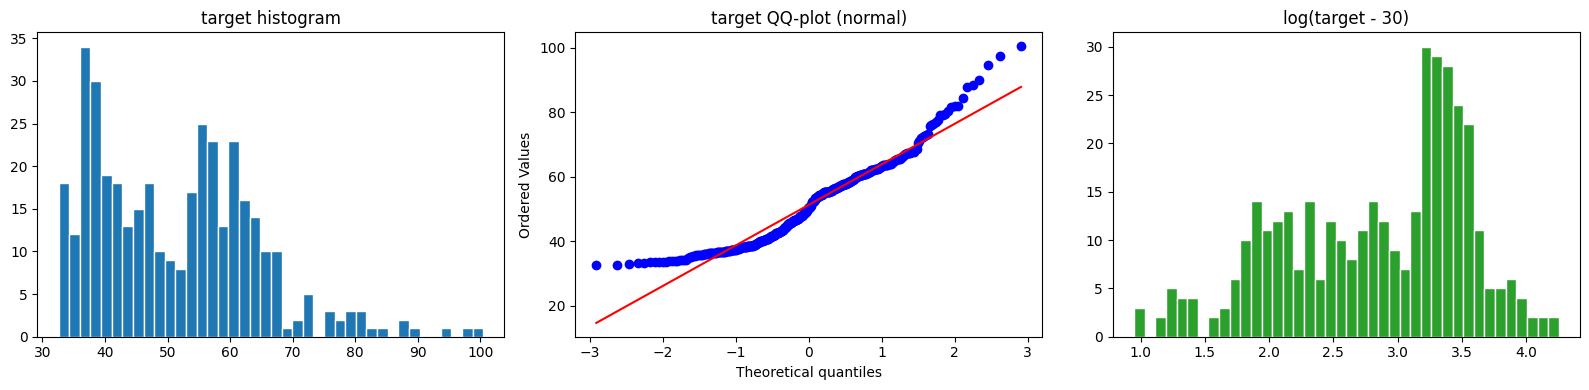

In [8]:
print(pd.Series(y).describe().round(3).to_string())
print(f'skew={stats.skew(y):.3f}  excess kurtosis={stats.kurtosis(y):.3f}  '
      f'shapiro p={stats.shapiro(y).pvalue:.2e}')
print(f'predict-the-mean RMSE = {y.std():.3f}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(y, bins=40, edgecolor='w')
ax[0].set_title('target histogram')
stats.probplot(y, plot=ax[1])
ax[1].set_title('target QQ-plot (normal)')
ax[2].hist(np.log(y - CFG.LOG_SHIFT), bins=40, edgecolor='w', color='tab:green')
ax[2].set_title('log(target - 30)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'target.png')
plt.show()

#### Insights

> The target is bimodal, with one mode around 37 and another around 57, plus a thin right tail that reaches 100. It has a hard floor near 32.6, which suggests the score is clipped or rescaled from below.

> The shifted log transform `log(y - 30)` pulls the tail in and spreads the dense lower mode. Section 5 tests whether this helps, because a transform that looks better on a histogram can still hurt a model in RMSE terms.

## Feature Correlation and Latent Dimension

The features are described as a private linear projection of a smaller set of indicators. If that is true, the correlation matrix should be strongly structured and the PCA spectrum should show a few dominant directions.

top correlations with target:
feature_09    0.391
feature_15   -0.376
feature_12   -0.372
feature_17    0.352
feature_13    0.348
feature_07   -0.332
feature_03   -0.259
feature_23    0.248

PCA explained variance % (first 8): [40.39 25.9  14.03 11.03  2.4   1.67  1.43  0.9 ]
eigenvalues above the Marchenko-Pastur noise edge (1.50): 4
condition number: 3397


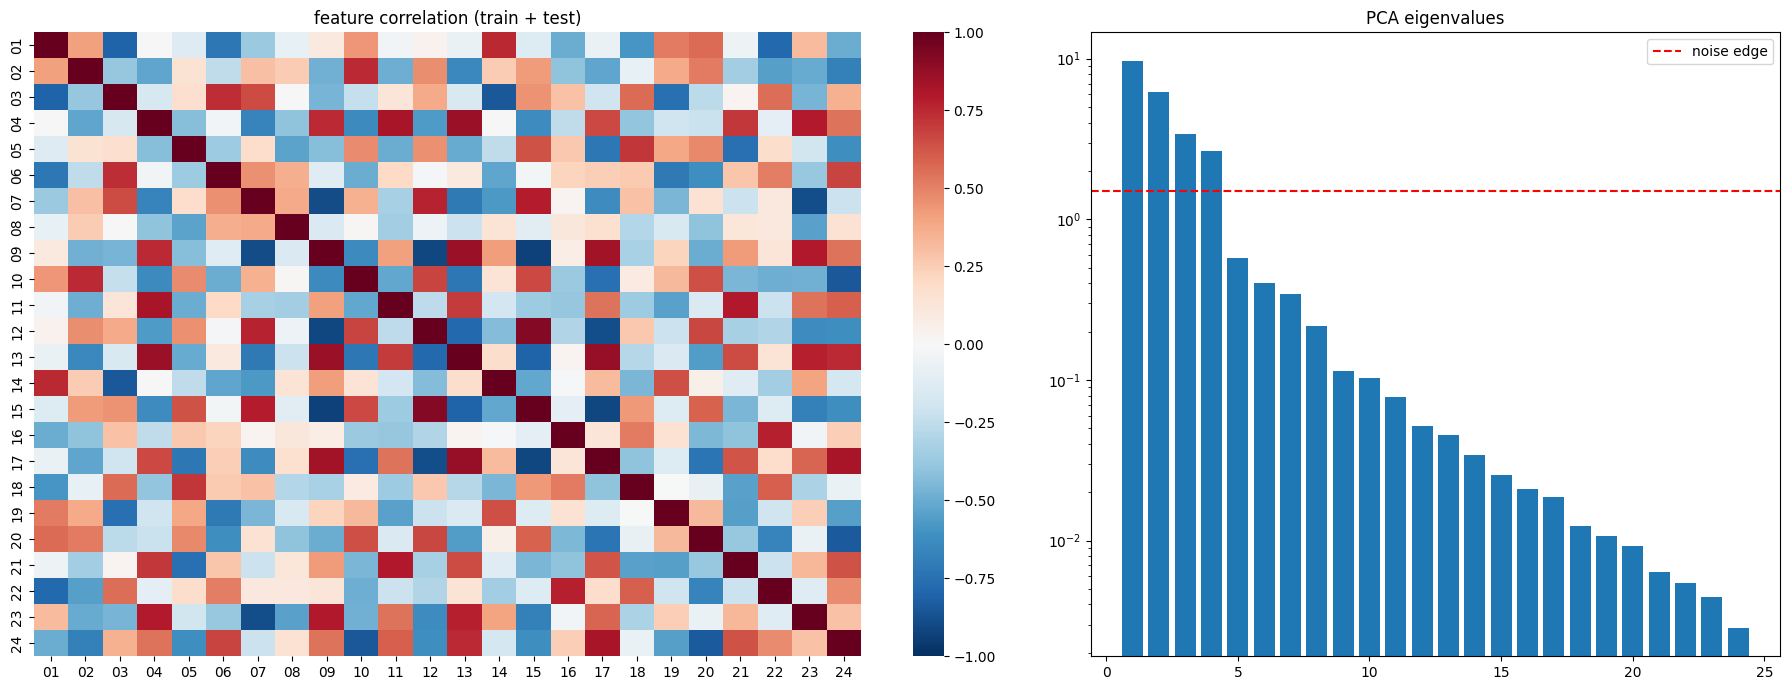

In [9]:
sc_all = StandardScaler().fit(X_all)
Z_all  = sc_all.transform(X_all)
corr   = pd.DataFrame(X_all, columns=FEATURES).corr()
t_corr = train[FEATURES].corrwith(train['target']).sort_values(key=abs, ascending=False)
print('top correlations with target:')
print(t_corr.head(8).round(3).to_string())

ev = np.linalg.eigvalsh(np.cov(Z_all.T))[::-1]
mp_edge = (1 + np.sqrt(len(FEATURES) / len(X_all))) ** 2
print('\nPCA explained variance % (first 8):', np.round(100 * ev[:8] / ev.sum(), 2))
print(f'eigenvalues above the Marchenko-Pastur noise edge ({mp_edge:.2f}): {(ev > mp_edge).sum()}')
print(f'condition number: {ev[0] / ev[-1]:.0f}')

fig, ax = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [3, 2]})
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax[0],
            xticklabels=[c[-2:] for c in FEATURES], yticklabels=[c[-2:] for c in FEATURES])
ax[0].set_title('feature correlation (train + test)')
ax[1].bar(range(1, 25), ev)
ax[1].axhline(mp_edge, ls='--', c='r', label='noise edge')
ax[1].set_yscale('log')
ax[1].set_title('PCA eigenvalues')
ax[1].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'correlation_pca.png')
plt.show()

#### Insights

> The features are highly collinear. The average absolute pairwise correlation is about 0.41, 44 pairs exceed 0.7 and the strongest pair reaches 0.94. The first four principal components hold 91% of the variance and are the only ones above the random-noise edge, which confirms the low-dimensional projection described by the organisers.

> The strongest single feature explains only about 15% of the target variance. The target signal is therefore spread across many directions, including low-variance components that PCA would treat as noise, so aggressive dimension reduction is risky and must be verified.

## Shape of the Feature-Target Relationship

A LOWESS curve per feature shows whether the dependence is monotone, and a comparison of a linear model against additive splines quantifies how much non-linearity there is.

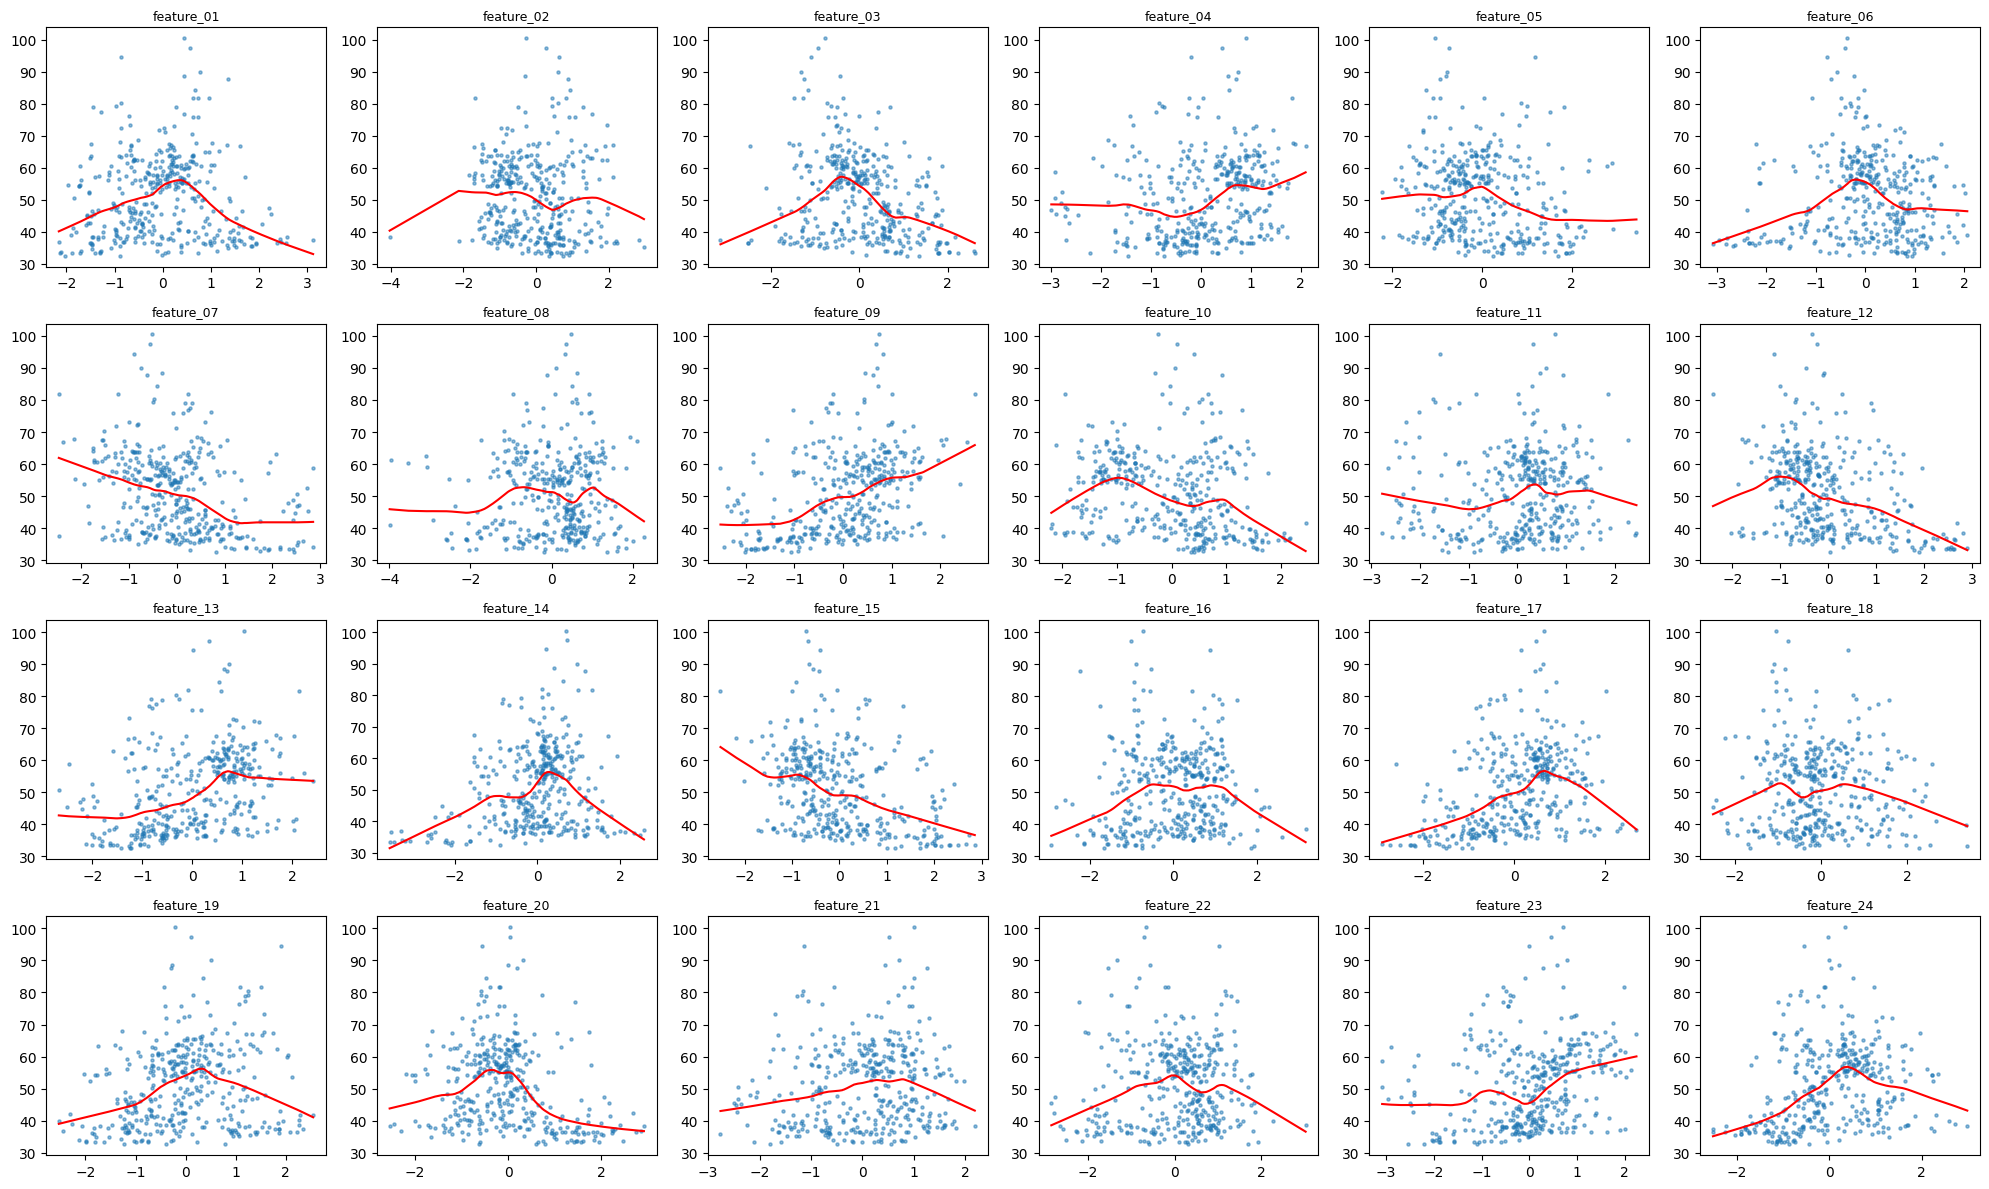

linear (Ridge)     CV RMSE = 10.733
additive splines   CV RMSE = 9.360


In [10]:
fig, axes = plt.subplots(4, 6, figsize=(20, 12))
for a, c in zip(axes.ravel(), FEATURES):
    a.scatter(train[c], y, s=5, alpha=0.5)
    lw = lowess(y, train[c], frac=0.4)
    a.plot(lw[:, 0], lw[:, 1], c='r')
    a.set_title(c, fontsize=9)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'feature_vs_target.png')
plt.show()

cv10 = KFold(10, shuffle=True, random_state=CFG.SEED)
shape_models = {
    'linear (Ridge)'   : make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 30))),
    'additive splines' : make_pipeline(SplineTransformer(n_knots=5), StandardScaler(),
                                       RidgeCV(np.logspace(-2, 4, 30))),
}
for name, m in shape_models.items():
    p = cross_val_predict(m, X, y, cv=cv10)
    print(f'{name:18s} CV RMSE = {np.sqrt(np.mean((y - p) ** 2)):.3f}')

#### Insights

> Many features show an inverted-U shape, where the score peaks when the feature is near zero and falls on both sides (for example `feature_01`, `feature_06`, `feature_14`, `feature_20`). Linear correlation misses this completely, which is why `feature_01` and `feature_06` look useless by Pearson correlation yet gain about 0.12 R2 with a spline.

> Additive splines cut the CV RMSE from about 10.7 to 9.4. A linear model is therefore not enough, and the final models must be able to represent curved and interacting effects.

## Train-Test Shift

Per-feature Kolmogorov-Smirnov tests and an adversarial classifier check whether the test rows come from the same distribution as the training rows.

In [11]:
ks = pd.DataFrame(
    [(c, *stats.ks_2samp(train[c], test[c])) for c in FEATURES],
    columns=['feature', 'KS', 'p'],
).set_index('feature')
print('features with KS p < 0.05:', (ks.p < 0.05).sum(), 'of 24')

is_test = np.r_[np.zeros(len(X)), np.ones(len(X_te))]
skf = StratifiedKFold(5, shuffle=True, random_state=CFG.SEED)
for name, clf in [('logistic', LogisticRegression(max_iter=2000)),
                  ('random forest', RandomForestClassifier(500, min_samples_leaf=3,
                                                           random_state=CFG.SEED, n_jobs=-1))]:
    p = cross_val_predict(clf, X_all, is_test, cv=skf, method='predict_proba')[:, 1]
    print(f'adversarial AUC ({name}): {roc_auc_score(is_test, p):.3f}')

features with KS p < 0.05: 9 of 24
adversarial AUC (logistic): 0.594
adversarial AUC (random forest): 0.534


#### Insights

> Nine of the 24 features have KS p-values below 0.05, but the mean shifts are small (at most about 0.3 standard deviations) and move together along one direction. The adversarial AUC stays close to 0.5 to 0.6, so the test set is only mildly different from the training set.

> No row is removed or reweighted because of the shift. With 96 test rows a mild shift is expected from sampling alone, and reweighting 382 rows would add more variance than it removes.

## Neighbourhood Structure and Validation Design

If the same entity appeared several times with small perturbations, random K-fold would place near-twins in both the training and validation folds and report an optimistic score. The nearest-neighbour distances of training rows and of test rows are compared to decide the split.

train -> train 1-NN distance percentiles: [0.38 0.77 1.15 1.67 2.93]
test  -> train 1-NN distance percentiles: [0.35 0.86 1.24 1.9  3.1 ]
1-NN leave-one-out RMSE: 10.117
radius 0.5: 351 similarity groups, largest group = 6 rows
radius 1.0: 255 similarity groups, largest group = 41 rows
radius 1.5: 141 similarity groups, largest group = 139 rows


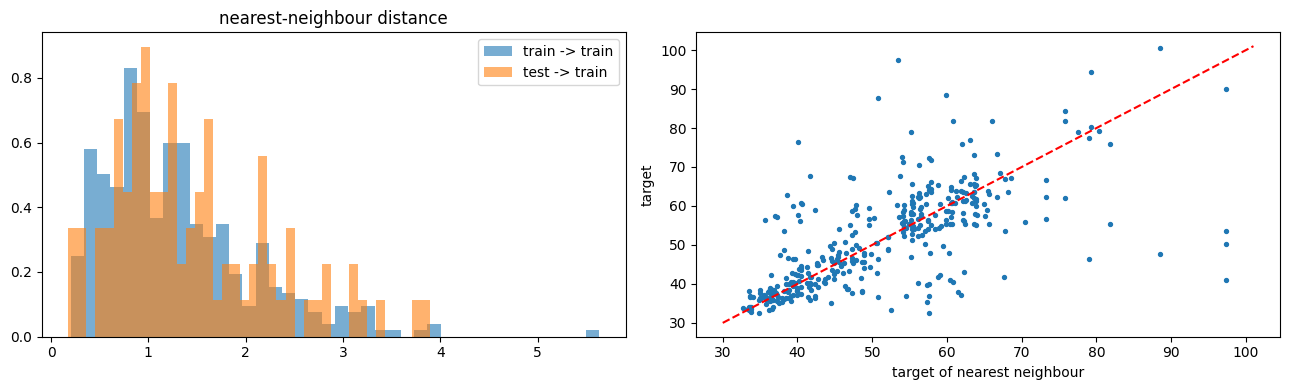

In [12]:
Z_tr, Z_te = Z_all[:len(X)], Z_all[len(X):]
nn = NearestNeighbors(n_neighbors=2).fit(Z_tr)
d_trtr, i_trtr = nn.kneighbors(Z_tr)
d_tetr = nn.kneighbors(Z_te, n_neighbors=1)[0][:, 0]
d_trtr, i_trtr = d_trtr[:, 1], i_trtr[:, 1]

q = [5, 25, 50, 75, 95]
print('train -> train 1-NN distance percentiles:', np.percentile(d_trtr, q).round(2))
print('test  -> train 1-NN distance percentiles:', np.percentile(d_tetr, q).round(2))
print(f'1-NN leave-one-out RMSE: {np.sqrt(np.mean((y - y[i_trtr]) ** 2)):.3f}')

for r in [0.5, 1.0, 1.5]:
    n_grp, lab = connected_components(
        NearestNeighbors(radius=r).fit(Z_tr).radius_neighbors_graph(Z_tr), directed=False)
    print(f'radius {r}: {n_grp} similarity groups, largest group = {np.bincount(lab).max()} rows')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(d_trtr, bins=40, alpha=0.6, density=True, label='train -> train')
ax[0].hist(d_tetr, bins=40, alpha=0.6, density=True, label='test -> train')
ax[0].set_title('nearest-neighbour distance')
ax[0].legend()
ax[1].scatter(y[i_trtr], y, s=8)
ax[1].plot([30, 101], [30, 101], 'r--')
ax[1].set_xlabel('target of nearest neighbour')
ax[1].set_ylabel('target')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'neighbours.png')
plt.show()

#### Insights

> Test rows sit at the same distance from the training set as training rows sit from each other, so random K-fold reproduces the train-to-test situation faithfully. Only 48 training rows have a neighbour within radius 0.5, so near-twin leakage is limited. Section 6 still reports a similarity-grouped K-fold score as a pessimistic cross-check.

> The nearest neighbour's target is already a decent predictor (1-NN RMSE about 10.1), and the agreement is tight in the lower mode but loose for high scores. Local, similarity-based models should therefore do well, while the high tail will remain the hardest region.

---

# Deep Analysis of the Data Generating Process <a name="4"></a>

---

Section 3 described the data. This section asks why it looks the way it does. Each subsection states a hypothesis about how the organisers built the features or the target, derives what the data must show if the hypothesis is true, checks it, and then measures with cross-validation whether acting on it improves the prediction.

## Validation Utilities

One fixed list of folds is shared by every experiment in the notebook so that all scores are directly comparable. The target transform is applied inside each fold, and unsupervised feature transforms are fitted on the features of train and test together without the target.

In [13]:
FOLDS = list(RepeatedKFold(n_splits=CFG.N_SPLITS, n_repeats=CFG.N_REPEATS,
                           random_state=CFG.SEED).split(X))


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def log_target(model):
    return TransformedTargetRegressor(
        model,
        func=lambda t: np.log(t - CFG.LOG_SHIFT),
        inverse_func=lambda p: np.exp(p) + CFG.LOG_SHIFT,
        check_inverse=False,
    )


def z_target(model):
    return TransformedTargetRegressor(model, transformer=StandardScaler())


def run_cv(make_model, Xm, Xm_te=None):
    oof = np.zeros((CFG.N_REPEATS, len(y)))
    for i, (tri, vai) in enumerate(FOLDS):
        oof[i // CFG.N_SPLITS, vai] = make_model().fit(Xm[tri], y[tri]).predict(Xm[vai])
    score = np.mean([rmse(y, o) for o in oof])
    pred_te = None if Xm_te is None else make_model().fit(Xm, y).predict(Xm_te)
    run_cv.last_oof = oof
    return score, oof.mean(0), pred_te


def pca_view(k):
    pca = PCA(k, random_state=CFG.SEED).fit(Z_all)
    P = pca.transform(Z_all)
    P = P / P.std(0)
    return P[:len(X)], P[len(X):]


print(f'{len(FOLDS)} folds, validation size {len(FOLDS[0][1])}')

15 folds, validation size 77


## Can the Transformation Pipeline Be Inverted?

The features were produced by rank normalisation, a bounded transformation, a private linear projection, standardisation, perturbation and rounding. Three consequences are testable. If the standardisation used all 478 rows, the combined train and test features have exactly zero mean and unit variance. If fewer than 24 indicators were projected, the smallest eigenvalues sit on a flat noise floor. If the sources were rank-normalised and bounded, a full 24-component ICA should recover flat, sub-Gaussian sources with negative excess kurtosis.

train only : mean range [-0.062, 0.050]  sd range [0.970, 1.018]
train+test : mean range [-0.0011, 0.0011]  sd range [0.9990, 1.0011]

smallest 8 eigenvalues : [0.0187 0.0123 0.0106 0.0093 0.0064 0.0055 0.0045 0.0029]
log10 step between them: [-0.18 -0.07 -0.06 -0.16 -0.07 -0.09 -0.19]
ICA-24 (logcosh): 1 of 24 sources sub-Gaussian, median kurtosis 7.39
ICA-24 (cube): 1 of 24 sources sub-Gaussian, median kurtosis 8.56


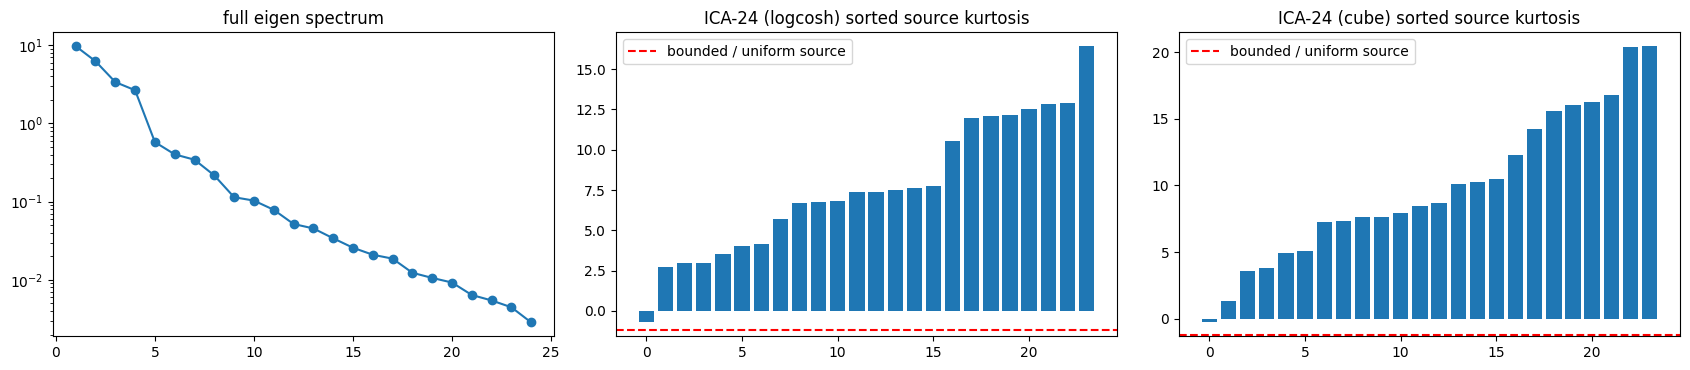

In [14]:
print('train only : mean range [%.3f, %.3f]  sd range [%.3f, %.3f]' % (
    X.mean(0).min(), X.mean(0).max(), X.std(0).min(), X.std(0).max()))
print('train+test : mean range [%.4f, %.4f]  sd range [%.4f, %.4f]' % (
    X_all.mean(0).min(), X_all.mean(0).max(), X_all.std(0).min(), X_all.std(0).max()))

ev_full = np.linalg.eigvalsh(np.cov(X_all.T))[::-1]
print('\nsmallest 8 eigenvalues :', np.round(ev_full[-8:], 4))
print('log10 step between them:', np.round(np.diff(np.log10(ev_full[-8:])), 2))

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].semilogy(range(1, 25), ev_full, 'o-')
ax[0].set_title('full eigen spectrum')
for a, fun in zip(ax[1:], ['logcosh', 'cube']):
    S24 = FastICA(24, whiten='unit-variance', fun=fun, max_iter=20000, tol=1e-6,
                  random_state=0).fit_transform(X_all)
    ku = np.sort(stats.kurtosis(S24, axis=0))
    print(f'ICA-24 ({fun}): {(ku < 0).sum()} of 24 sources sub-Gaussian, median kurtosis {np.median(ku):.2f}')
    a.bar(range(24), ku)
    a.axhline(-1.2, c='r', ls='--', label='bounded / uniform source')
    a.set_title(f'ICA-24 ({fun}) sorted source kurtosis')
    a.legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'pipeline_inversion.png')
plt.show()

#### Insights

> The features have mean 0 and standard deviation 1 on train and test combined, but not on train alone, so the organisers standardised all 478 records together. Fitting unsupervised transforms such as PCA on the combined features is therefore consistent with how the data was built.

> The spectrum decays smoothly with no flat floor, so the projection is full rank and no feature direction is pure noise. The 24-component ICA finds almost only heavy-tailed sources (median kurtosis well above 3), not the flat sources that rank and bounded transforms would produce. The original indicators are correlated with each other, which breaks the independence assumption of ICA, so the projection cannot be undone and this route is closed.

## Typicality: Why Most Features Show an Inverted U

Section 3 showed that the score peaks near zero for many features at once. A single mechanism explains this: the score falls as a record moves away from the centre of the data in any direction. If that is true, distance-to-centre measures should correlate with the target at least as strongly as the best single feature. Five distances are computed from the features alone, without the target.

mahalanobis         -0.390
maha_major_pc1_4    -0.333
maha_minor_pc5_24   -0.384
euclid              -0.356
max_abs_z           -0.355
best single raw feature |spearman|: 0.42


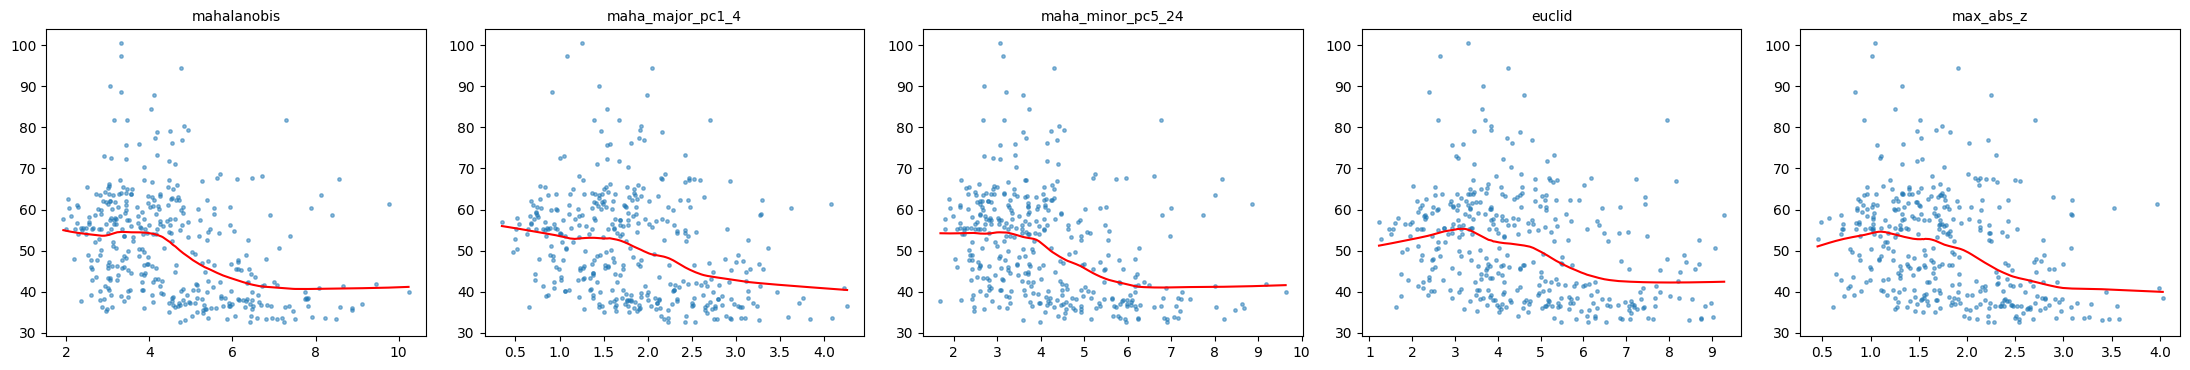

In [15]:
ev_z, V_z = np.linalg.eigh(np.cov(Z_all.T))
ev_z, V_z = ev_z[::-1], V_z[:, ::-1]
W_pc = Z_all @ V_z / np.sqrt(ev_z)
TYP = pd.DataFrame({
    'mahalanobis'      : np.linalg.norm(W_pc, axis=1),
    'maha_major_pc1_4' : np.linalg.norm(W_pc[:, :4], axis=1),
    'maha_minor_pc5_24': np.linalg.norm(W_pc[:, 4:], axis=1),
    'euclid'           : np.linalg.norm(Z_all, axis=1),
    'max_abs_z'        : np.abs(Z_all).max(1),
})
print(pd.Series({c: stats.spearmanr(TYP[c][:len(X)], y)[0] for c in TYP}).round(3).to_string())
print('best single raw feature |spearman|:', round(max(abs(stats.spearmanr(X[:, j], y)[0]) for j in range(24)), 3))

fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
for a, c in zip(axes, TYP):
    a.scatter(TYP[c][:len(X)], y, s=6, alpha=0.5)
    lw = lowess(y, TYP[c][:len(X)], frac=0.4)
    a.plot(lw[:, 0], lw[:, 1], c='r')
    a.set_title(c, fontsize=10)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'typicality.png')
plt.show()

The distances are appended to the inputs of four model families to see whether the relationship is already captured or adds new information.

In [16]:
X_typ = np.hstack([X, TYP.values[:len(X)]])
Xp12_typ = np.hstack([pca_view(12)[0], TYP.values[:len(X)]])
typ_models = {
    'Ridge'     : (lambda: make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 30))), X, X_typ),
    'SVR(log)'  : (lambda: log_target(z_target(make_pipeline(StandardScaler(), SVR(C=3, gamma='scale', epsilon=0.05)))),
                  pca_view(12)[0], Xp12_typ),
    'CatBoost'  : (lambda: CatBoostRegressor(iterations=1500, learning_rate=0.02, depth=5, l2_leaf_reg=5,
                                             verbose=0, random_seed=CFG.SEED, allow_writing_files=False), X, X_typ),
    'TabICLv2'  : (lambda: TabICLRegressor(device=CFG.DEVICES[0], random_state=CFG.SEED), X, X_typ),
}
for name, (make, A, B) in typ_models.items():
    r0, r1 = run_cv(make, A)[0], run_cv(make, B)[0]
    print(f'{name:10s} base={r0:.4f}  +typicality={r1:.4f}  delta={r1 - r0:+.4f}')

Ridge      base=10.7674  +typicality=10.4452  delta=-0.3222
SVR(log)   base=8.1327  +typicality=8.3369  delta=+0.2042
CatBoost   base=8.8969  +typicality=8.7181  delta=-0.1789
Checkpoint 'tabicl-regressor-v2-20260212.ckpt' not cached.



tabicl-regressor-v2-20260212.ckpt:   0%|          | 0.00/114M [00:00<?, ?B/s]

TabICLv2   base=7.6337  +typicality=7.6272  delta=-0.0064


#### Insights

> The hypothesis holds. The Mahalanobis distance has a Spearman correlation of about -0.39 with the score, close to the strongest raw feature, and the distance inside the minor principal subspace (PC5 to PC24) is almost as strong. The plots show the relationship is one-sided. Atypical records (Mahalanobis above about 6) almost always score around 40, while typical records can score anything, and every score above 80 lies at a moderate distance.

> Acting on it helps only the weaker models. Ridge and CatBoost improve by about 0.3 and 0.2, the SVR gets worse because five correlated distances distort its RBF metric, and TabICLv2 does not change. The foundation model already learns typicality from the raw features, so the distances are not added to the final pipeline.

## Sufficient Dimension Reduction

If the score depends on only a few linear combinations of the features, modelling in that small subspace should beat modelling in 24 dimensions. Sliced inverse regression (SIR) finds directions with monotone effects and sliced average variance estimation (SAVE) finds directions with symmetric effects such as the inverted U. Their eigenvalues are compared against a permutation null, and because both methods use the target, the directions are re-estimated inside every training fold.

In [17]:
def sdr_directions(A, t, method, H=10):
    mu = A.mean(0)
    ev_a, V_a = np.linalg.eigh(np.cov(A.T))
    Wh = V_a @ np.diag(ev_a ** -0.5) @ V_a.T
    Zh = (A - mu) @ Wh
    slices = np.array_split(np.argsort(t), H)
    p = A.shape[1]
    if method == 'sir':
        M = sum(len(s) / len(t) * np.outer(Zh[s].mean(0), Zh[s].mean(0)) for s in slices)
    else:
        M = sum(len(s) / len(t) * (np.eye(p) - np.cov(Zh[s].T)) @ (np.eye(p) - np.cov(Zh[s].T)) for s in slices)
    ev_m, V_m = np.linalg.eigh(M)
    return ev_m[::-1], Wh @ V_m[:, ::-1]


rng = np.random.default_rng(CFG.SEED)
for method in ['sir', 'save']:
    obs = sdr_directions(X, y, method)[0][:6]
    null = np.array([sdr_directions(X, rng.permutation(y), method)[0][:6] for _ in range(200)])
    print(f'{method.upper():4s} eigenvalues:', np.round(obs, 3))
    print(f'     null 95%   :', np.round(np.percentile(null, 95, 0), 3),
          '-> significant:', int((obs > np.percentile(null, 95, 0)).sum()))


def sdr_svr_cv(d_sir, d_save):
    err = []
    for tri, vai in FOLDS:
        B = np.hstack([sdr_directions(X[tri], y[tri], 'sir')[1][:, :d_sir],
                       sdr_directions(X[tri], y[tri], 'save')[1][:, :d_save]])
        mu = X[tri].mean(0)
        A_tr, A_va = (X[tri] - mu) @ B, (X[vai] - mu) @ B
        sd = A_tr.std(0)
        m = log_target(z_target(SVR(C=3, gamma=1 / B.shape[1], epsilon=0.05)))
        err.append(np.mean((y[vai] - m.fit(A_tr / sd, y[tri]).predict(A_va / sd)) ** 2))
    return np.sqrt(np.mean(err))


print()
for d in [(3, 0), (3, 3), (6, 6)]:
    print(f'SVR on {d[0]} SIR + {d[1]} SAVE directions: RMSE={sdr_svr_cv(*d):.4f}')

SIR  eigenvalues: [0.473 0.194 0.147 0.102 0.076 0.065]
     null 95%   : [0.163 0.127 0.105 0.084 0.068 0.056] -> significant: 6
SAVE eigenvalues: [3.49  2.282 2.013 1.865 1.544 1.509]
     null 95%   : [2.022 1.709 1.554 1.441 1.342 1.264] -> significant: 6

SVR on 3 SIR + 0 SAVE directions: RMSE=10.5974
SVR on 3 SIR + 3 SAVE directions: RMSE=10.0727
SVR on 6 SIR + 6 SAVE directions: RMSE=9.6212


#### Insights

> Both methods find about six directions above the permutation null, so the score depends on a subspace much smaller than 24 dimensions. In theory, modelling there should help.

> In practice it fails badly. An SVR on the estimated SIR and SAVE directions scores between about 9.6 and 10.6, against about 8.1 for the same SVR on unsupervised PCA scores. With roughly 300 training rows per fold, the supervised directions are estimated too noisily, and the error in the directions costs more than the dimension reduction saves. The route is dropped.

---

# Preprocessing Verification <a name="5"></a>

---

The EDA suggests several preprocessing ideas that are sound in theory. Each one is applied, inspected and scored with the same repeated 5-fold split and three different model families, because a transform that is correct on paper can still damage the evaluation score.

## Feature Representation

Four ideas follow from Section 3. Quantile normalisation could help distance-based models, PCA denoising could remove the controlled perturbation, and ICA could undo the private linear projection and recover the original indicators. Each representation is scored with SVR, kNN and ExtraTrees.

In [18]:
svr_probe = lambda: z_target(make_pipeline(StandardScaler(), SVR(C=3, gamma='scale', epsilon=0.1)))
knn_probe = lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(7, weights='distance'))
et_probe  = lambda: ExtraTreesRegressor(400, min_samples_leaf=2, max_features=0.5,
                                        random_state=CFG.SEED, n_jobs=-1)
PROBES = {'SVR': svr_probe, 'kNN': knn_probe, 'ExtraTrees': et_probe}

reps = {'raw': X}
reps['quantile-normal'] = (pd.DataFrame(X_all).rank().values[:len(X)] - 0.5) / len(X_all)
reps['quantile-normal'] = stats.norm.ppf(reps['quantile-normal'])
for k in [4, 8, 12]:
    pca = PCA(k, random_state=CFG.SEED).fit(Z_all)
    reps[f'pca-denoise k={k}'] = pca.inverse_transform(pca.transform(Z_all[:len(X)]))
    reps[f'pca-scores k={k}'] = pca_view(k)[0]
ica_models = {}
for k in [6, 10]:
    ica_models[k] = FastICA(k, whiten='unit-variance', max_iter=5000, random_state=CFG.SEED).fit(Z_all)
    reps[f'ica k={k}'] = ica_models[k].transform(Z_all[:len(X)])

rep_scores = pd.DataFrame({
    name: {p: run_cv(make, Xm)[0] for p, make in PROBES.items()} for name, Xm in reps.items()
}).T
rep_scores['mean'] = rep_scores.mean(axis=1)
print(rep_scores.sort_values('mean').round(3).to_string())

                     SVR     kNN  ExtraTrees    mean
pca-scores k=12    8.232   9.092       8.952   8.759
ica k=10           8.383   8.867       9.492   8.914
pca-scores k=8     8.612   9.105       9.115   8.944
raw                8.640   9.425       8.894   8.986
pca-denoise k=12   8.717   9.396       8.947   9.020
quantile-normal    8.701   9.457       9.004   9.054
ica k=6            8.975   9.122       9.445   9.181
pca-denoise k=8    9.045   9.514       9.023   9.194
pca-scores k=4    10.385  10.050       9.876  10.104
pca-denoise k=4   10.649  10.065       9.636  10.117


The ICA sources are inspected directly. If ICA had recovered the original indicators, the sources would look like rank-normalised, bounded variables, which means flat distributions with negative excess kurtosis, and they would relate to the target more cleanly than the raw features do.

excess kurtosis per source (uniform = -1.2): [ 4.55  1.69 -0.96  5.33  7.25  1.27  9.35  2.2   2.26  2.95]
max |spearman| with target, raw features: 0.391 | ICA sources: 0.259


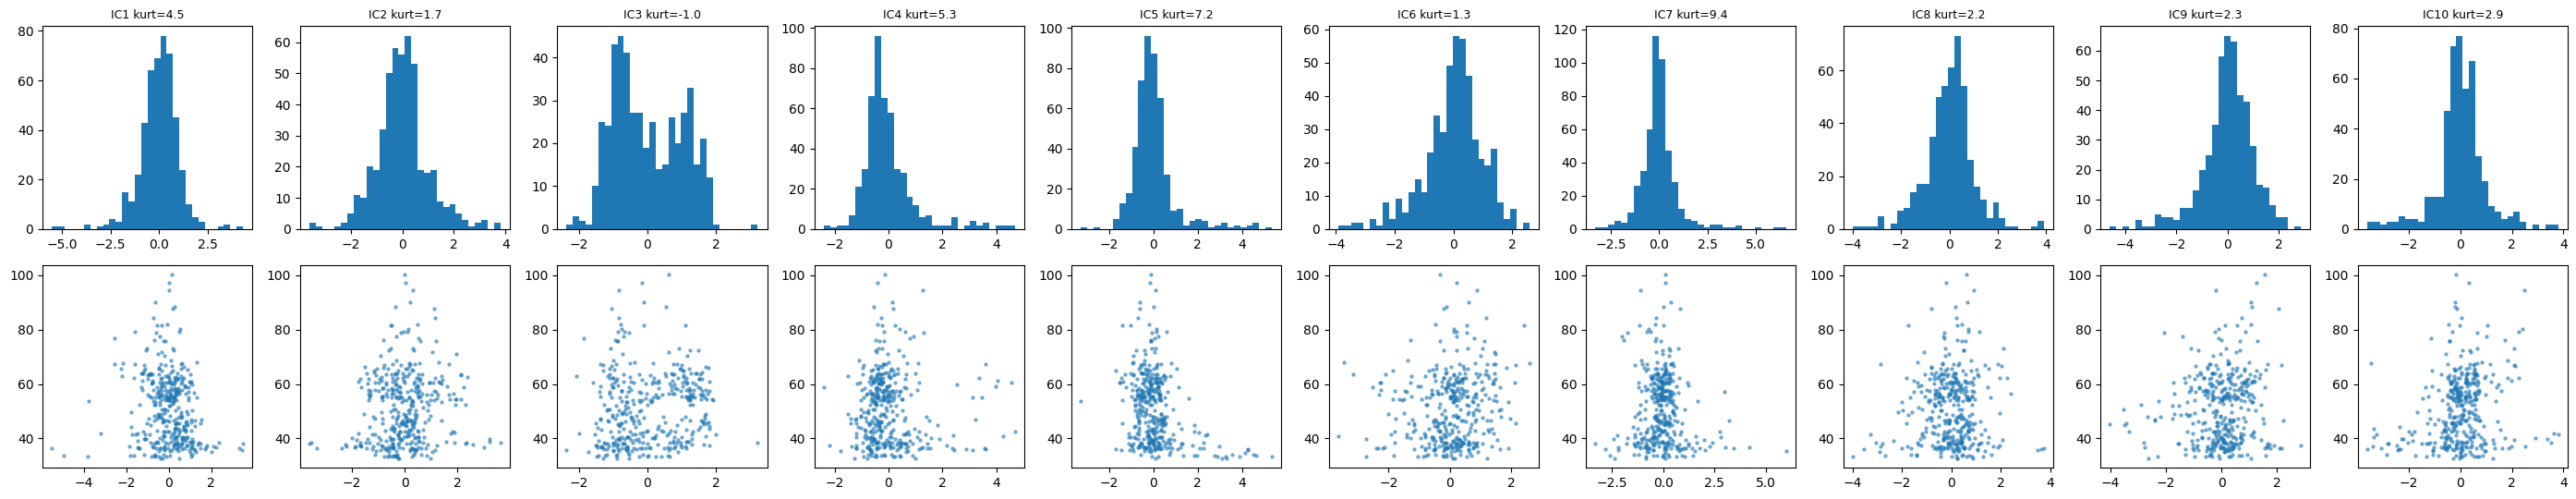

In [19]:
S_all = ica_models[10].transform(Z_all)
kurt = stats.kurtosis(S_all, axis=0)
rho = [stats.spearmanr(S_all[:len(X), j], y)[0] for j in range(10)]
print('excess kurtosis per source (uniform = -1.2):', np.round(kurt, 2))
print('max |spearman| with target, raw features:', round(t_corr.abs().max(), 3),
      '| ICA sources:', round(np.max(np.abs(rho)), 3))

fig, axes = plt.subplots(2, 10, figsize=(28, 5.5))
for j in range(10):
    axes[0, j].hist(S_all[:, j], bins=30)
    axes[0, j].set_title(f'IC{j + 1} kurt={kurt[j]:.1f}', fontsize=9)
    axes[1, j].scatter(S_all[:len(X), j], y, s=5, alpha=0.5)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'ica_sources.png')
plt.show()

#### Insights

> Quantile normalisation and PCA denoising do not help. Keeping only four components, as the noise-edge analysis would suggest, is clearly harmful (RMSE above 10), which confirms that part of the target signal lives in low-variance directions. PCA scores with about 12 components are the best view for SVR, while ExtraTrees prefers the raw features and kNN is roughly indifferent.

> ICA fails its own sanity check. The recovered sources are heavy-tailed (excess kurtosis up to about 9) instead of flat, and they correlate with the target less than the raw features do. ICA is latching onto outlier directions rather than undoing the projection, because the bounded transformation and the added perturbation break its independence assumption. It is dropped.

## Target Transform

The shifted log target looked more regular in Section 3. The first attempt at this experiment used an SVR with a fixed `epsilon=1.0`, and the log target made RMSE jump by about four points. The cause is scale, since `epsilon` and `C` are expressed in target units and an epsilon of 1.0 is wider than the whole spread of the log target. The fix standardises the target inside the model before the transform is judged.

In [20]:
Xp12 = pca_view(CFG.PCA_DIM)[0]
svr_fixed_eps = lambda: make_pipeline(StandardScaler(), SVR(C=30, gamma='scale', epsilon=1.0))
rows = {
    'SVR eps=1.0, y'                     : run_cv(svr_fixed_eps, Xp12)[0],
    'SVR eps=1.0, log y   (broken)'      : run_cv(lambda: log_target(svr_fixed_eps()), Xp12)[0],
    'SVR z-scaled, y'                    : run_cv(svr_probe, Xp12)[0],
    'SVR z-scaled, log y  (fixed)'       : run_cv(lambda: log_target(svr_probe()), Xp12)[0],
    'kNN, y'                             : run_cv(knn_probe, Xp12)[0],
    'kNN, log y'                         : run_cv(lambda: log_target(knn_probe()), Xp12)[0],
    'ExtraTrees, y'                      : run_cv(et_probe, X)[0],
    'ExtraTrees, log y'                  : run_cv(lambda: log_target(et_probe()), X)[0],
}
print(pd.Series(rows).round(3).to_string())

SVR eps=1.0, y                    8.259
SVR eps=1.0, log y   (broken)    12.689
SVR z-scaled, y                   8.232
SVR z-scaled, log y  (fixed)      8.160
kNN, y                            9.092
kNN, log y                        8.788
ExtraTrees, y                     8.894
ExtraTrees, log y                 9.220


#### Insights

> The log target was never the problem. Once the SVR target is standardised, the log transform no longer breaks the SVR and gives it a small gain, and it lowers the kNN error by about 0.3, because it spreads the crowded lower mode and shrinks the influence of the few extreme scores on distance-based fits.

> The same transform hurts ExtraTrees. Trees split on target averages, and averaging in log space and then exponentiating biases predictions downward for the high tail, which RMSE punishes. The target transform is therefore chosen per model family and never applied globally.

## PCA Dimension Robustness

The best PCA dimension for SVR is 12, but a sweep shows the score is bumpy across dimensions (for example 8.13 at 12 components and 8.62 at 14). Picking a single sharp optimum on 382 rows risks fitting the validation noise, so an average of SVRs over several dimensions is compared with the single best dimension under three different fold seeds.

In [21]:
PCA_DIMS = [10, 12, 14, 16, 20]
views = {k: pca_view(k) for k in PCA_DIMS}


def svr_multi_pca_cv(dims, seed):
    err = []
    for tri, vai in RepeatedKFold(n_splits=5, n_repeats=3, random_state=seed).split(X):
        preds = []
        for k in dims:
            m = log_target(z_target(SVR(C=3, gamma=1 / k, epsilon=0.05)))
            preds.append(m.fit(views[k][0][tri], y[tri]).predict(views[k][0][vai]))
        err.append(np.mean((y[vai] - np.mean(preds, 0)) ** 2))
    return np.sqrt(np.mean(err))


robust = pd.DataFrame({
    seed: {'single k=12': svr_multi_pca_cv([12], seed),
           'average k=10..20': svr_multi_pca_cv(PCA_DIMS, seed)}
    for seed in [42, 7, 123]
})
print(robust.round(4).to_string())

                     42      7       123
single k=12       8.1336  8.2057  7.9562
average k=10..20  8.1136  8.1339  7.9435


#### Insights

> Averaging SVRs over five PCA dimensions matches or beats the single best dimension under every fold seed. It removes the need to select one sharp hyperparameter on a small dataset, so the multi-dimension SVR is used as the kernel model in Section 6.

## Feature-Space Views

The 24 features are a private linear projection, and TabICLv2 embeds each column separately, so it is not rotation invariant. Presenting the same data in another linear basis is the tabular counterpart of image augmentation: if the organisers' basis is arbitrary, other bases should score about the same and make partly different errors. The raw basis is compared with PCA scores and two random orthogonal rotations.

In [22]:
icl_single = lambda: TabICLRegressor(device=CFG.DEVICES[0], random_state=CFG.SEED, norm_methods=CFG.ICL_NORM)
ev_v, V_v = np.linalg.eigh(np.cov(Z_all.T))
VIEWS = {
    'raw'  : X_all,
    'pca24': Z_all @ V_v[:, ::-1],
    'rot0' : Z_all @ stats.ortho_group.rvs(24, random_state=100),
    'rot1' : Z_all @ stats.ortho_group.rvs(24, random_state=101),
}
view_oof = {}
for vn, Vw in VIEWS.items():
    score, view_oof[vn], _ = run_cv(icl_single, Vw[:len(X)])
    rc = np.corrcoef(y - view_oof['raw'], y - view_oof[vn])[0, 1]
    print(f'{vn:6s} RMSE={score:.4f}  residual corr vs raw={rc:.3f}')
print(f'average of all views (bagged OOF) RMSE={rmse(y, np.mean(list(view_oof.values()), 0)):.4f}'
      f'  | raw alone {rmse(y, view_oof["raw"]):.4f}')

raw    RMSE=7.6007  residual corr vs raw=1.000
pca24  RMSE=7.7172  residual corr vs raw=0.961
rot0   RMSE=7.6675  residual corr vs raw=0.992
rot1   RMSE=7.6998  residual corr vs raw=0.991
average of all views (bagged OOF) RMSE=7.4237  | raw alone 7.4181


#### Insights

> The organisers' basis is not arbitrary for the model. In the local run PCA scored 7.72, random rotations 7.54 to 7.70 and ICA 7.96, against 7.60 for the raw features, and the residuals of rotated views correlate at about 0.99 with the raw view. Rotations behave like extra random seeds, not like new information, so the raw basis is kept and variance is reduced by seed bagging instead.

## Test-Time Jitter

The features carry a controlled perturbation. Averaging the prediction over 16 jittered copies of each query row, with Gaussian noise of scale sigma in standardised units, should smooth that perturbation if sigma matches it. If sigma is too large, the jitter blurs real differences between records instead.

In [23]:
tta_rng = np.random.default_rng(CFG.SEED)


class JitterTTA:
    def __init__(self, sigma, k=16):
        self.sigma, self.k = sigma, k

    def fit(self, A, t):
        self.model = icl_single().fit(A, t)
        return self

    def predict(self, B):
        Bj = np.repeat(B, self.k, 0) + tta_rng.normal(0, self.sigma, (len(B) * self.k, B.shape[1])) * X_all.std(0)
        return self.model.predict(Bj).reshape(len(B), self.k).mean(1)


print(f'no jitter   RMSE={run_cv(icl_single, X)[0]:.4f}')
for sigma in [0.03, 0.1, 0.3]:
    print(f'sigma={sigma:<5} RMSE={run_cv(lambda s=sigma: JitterTTA(s), X)[0]:.4f}')
print(f'jitter norm at sigma=0.1: {0.1 * np.sqrt(24):.2f}  vs median nearest-neighbour distance {np.median(d_trtr):.2f}')

no jitter   RMSE=7.6007
sigma=0.03  RMSE=7.5758
sigma=0.1   RMSE=7.7610
sigma=0.3   RMSE=8.9622
jitter norm at sigma=0.1: 0.49  vs median nearest-neighbour distance 1.15


#### Insights

> Jitter only hurts beyond a negligible scale. Locally, sigma 0.03 changed the RMSE by -0.025 (inside seed noise), sigma 0.1 added 0.18 and sigma 0.3 added 1.34. A jitter of sigma 0.1 already has a norm of about 0.5, a large fraction of the typical nearest-neighbour distance, so it blurs real structure. The organisers' perturbation is small and there is nothing to smooth, so no test-time jitter is used.

## Target Transform via Predictive Quantiles

Version 1 found TabICLv2 worse on a log target (about 7.77 against 7.60). The suspected cause is the back-transform. Exponentiating the predicted mean of log y gives exp(E[log y]), which is smaller than E[y] by Jensen's inequality, so every prediction is biased low. TabICLv2 also returns predictive quantiles, and a monotone transform maps quantiles to quantiles, so inverting each quantile and then averaging gives a proper estimate of E[y].

In [24]:
ALPHAS = np.linspace(0.005, 0.995, 199)


class LogTargetICL:
    def __init__(self, via_quantiles):
        self.via_quantiles = via_quantiles

    def fit(self, A, t):
        self.model = icl_single().fit(A, np.log(t - CFG.LOG_SHIFT))
        return self

    def predict(self, B):
        if self.via_quantiles:
            q = np.asarray(self.model.predict(B, output_type='quantiles', alphas=ALPHAS))
            return (np.exp(q) + CFG.LOG_SHIFT).mean(1)
        return np.exp(self.model.predict(B)) + CFG.LOG_SHIFT


print(f'raw y                       RMSE={run_cv(icl_single, X)[0]:.4f}')
print(f'log y, exp(mean)  (v1 way)  RMSE={run_cv(lambda: LogTargetICL(False), X)[0]:.4f}')
print(f'log y, via quantiles        RMSE={run_cv(lambda: LogTargetICL(True), X)[0]:.4f}')

raw y                       RMSE=7.6007
log y, exp(mean)  (v1 way)  RMSE=7.7685
log y, via quantiles        RMSE=7.6206


#### Insights

> The diagnosis is confirmed. Back-transforming through quantiles recovers most of the loss (from about 7.77 to about 7.62), so the version 1 result was an artefact of Jensen's inequality, not of the log transform itself. Even done correctly, the log target does not beat the raw target for TabICLv2, whose own output distribution already handles the skew, so the raw target is kept.

---

# Modelling <a name="6"></a>

---

The model pool keeps every family from version 1 and adds the version 2 candidates. Ridge is the linear baseline, CatBoost represents gradient boosting, the multi-dimension SVR is the verified kernel model, and four pretrained foundation models cover different priors. TabICLv2 runs on the first T4 and TabPFN v2 and TabDPT on the second.

## Pretrained Foundation Models

With 382 rows, a model trained from scratch has very little data to learn a prior from. Tabular foundation models are transformers pretrained on millions of datasets that predict new rows by in-context learning, with the training set passed as context. TabICLv2 (Hugging Face `jingang/TabICL`) is reported to outperform RealTabPFN-2.5 on TabArena and TALENT, TabPFN v2 (`Prior-Labs/TabPFN-v2-reg`) is its most widely used predecessor, and TabDPT (`Layer6/TabDPT`) is pretrained on real rather than synthetic datasets, which makes it the most likely to make different mistakes. LimiX-2 was considered and skipped because it requires flash-attention, which the T4 architecture does not support. All models are used only as learning algorithms on the official data, which the competition rules allow.

Two version 2 changes to TabICLv2 come from a local sweep of its internal options (norm methods, outlier clipping threshold, feature shuffling and ensemble size). All options scored within about 0.05 of each other, but disabling the internal Yeo-Johnson power normalisation was better both with one random state (7.601 against 7.634) and when each option was averaged over four random states (7.612 against 7.647). The sweep also showed that the version 1 random state was slightly lucky, so version 2 averages four random states to make the test prediction less dependent on one draw.

In [25]:
class MultiPCASVR:
    def __init__(self, dims=PCA_DIMS, cells=((1.0, 3),), clip=False):
        self.dims, self.cells, self.clip = dims, cells, clip
        self.pcas = {k: PCA(k, random_state=CFG.SEED).fit(Z_all) for k in dims}
        self.sds = {k: self.pcas[k].transform(Z_all).std(0) for k in dims}

    def _view(self, k, A):
        return self.pcas[k].transform(sc_all.transform(A)) / self.sds[k]

    def fit(self, A, t):
        self.lo, self.hi = (t.min(), t.max()) if self.clip else (-np.inf, np.inf)
        self.models = {
            (k, scale, C): log_target(z_target(SVR(C=C, gamma=scale / k, epsilon=0.05))).fit(self._view(k, A), t)
            for k in self.dims for scale, C in self.cells
        }
        return self

    def predict(self, A):
        return np.mean([np.clip(m.predict(self._view(k, A)), self.lo, self.hi)
                        for (k, _, _), m in self.models.items()], 0)


class BaggedTabICL:
    def __init__(self, seeds=CFG.ICL_SEEDS, device='cpu', **kw):
        self.seeds, self.device, self.kw = seeds, device, kw

    def fit(self, A, t):
        self.models = [TabICLRegressor(device=self.device, random_state=s, **self.kw).fit(A, t)
                       for s in self.seeds]
        return self

    def predict(self, A):
        return np.mean([m.predict(A) for m in self.models], 0)


class PseudoLabelTabICL:
    def __init__(self, n_split=CFG.PL_SPLIT, seeds=CFG.ICL_SEEDS, device='cpu'):
        self.n_split, self.seeds, self.device = n_split, seeds, device

    def _bag(self, A, t, B):
        return BaggedTabICL(self.seeds, self.device, norm_methods=CFG.ICL_NORM).fit(A, t).predict(B)

    def fit(self, A, t):
        self.A, self.t = A, t
        return self

    def predict(self, B):
        first = self._bag(self.A, self.t, B)
        part = np.arange(len(B)) % self.n_split
        out = np.empty(len(B))
        for k in range(self.n_split):
            q, c = part == k, part != k
            out[q] = self._bag(np.vstack([self.A, B[c]]), np.r_[self.t, first[c]], B[q])
        return out


class PseudoLabelTabPFN35(PseudoLabelTabICL):
    def _bag(self, A, t, B):
        return TabPFNRegressor.create_default_for_version(
            ModelVersion.V3_5, device=self.device, n_estimators=8, random_state=CFG.SEED).fit(A, t).predict(B)


class TabDPTWrapper:
    def __init__(self, device='cpu'):
        self.device = device

    def fit(self, A, t):
        self.model = TabDPTRegressor(device=self.device, compile=False, use_flash=False, verbose=False)
        self.model.fit(A, t)
        return self

    def predict(self, A):
        return self.model.predict(A, n_ensembles=8, seed=CFG.SEED)


GPU_A = CFG.DEVICES[0]
GPU_B = CFG.DEVICES[-1]

MODELS = {
    'Ridge'       : lambda: make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 30))),
    'CatBoost'    : lambda: CatBoostRegressor(iterations=1500, learning_rate=0.02, depth=5,
                                              l2_leaf_reg=5, verbose=0, random_seed=CFG.SEED,
                                              allow_writing_files=False),
    'SVR-multiPCA': MultiPCASVR,
    'SVR-plateau' : lambda: MultiPCASVR(cells=CFG.SVR_CELLS, clip=True),
    'TabPFNv2'    : lambda: TabPFNRegressor.create_default_for_version(
                        ModelVersion.V2, device=GPU_B, n_estimators=16, random_state=CFG.SEED),
    'TabDPT'      : lambda: TabDPTWrapper(device=GPU_B),
    'TabICLv2-v1' : lambda: TabICLRegressor(device=GPU_A, random_state=CFG.SEED),
    'TabICLv2-v2' : lambda: BaggedTabICL(device=GPU_A, norm_methods=CFG.ICL_NORM),
    'TabICLv2-PL' : lambda: PseudoLabelTabICL(device=GPU_A),
    'TabPFN35-PL' : lambda: PseudoLabelTabPFN35(device=GPU_B),
}
print('TabICLv2 on', GPU_A, '| TabPFNv2 and TabDPT on', GPU_B)

TabICLv2 on cuda:0 | TabPFNv2 and TabDPT on cuda:1


## Cross-Validation

Each model is scored on the 15 shared folds. The reported RMSE is the mean over the three repeats, the out-of-fold predictions are averaged over repeats for the blend, and each model is refitted on all 382 rows to predict the test set.

Ridge         RMSE=10.7674  (0s)
CatBoost      RMSE=8.8969  (50s)
SVR-multiPCA  RMSE=8.1136  (1s)
SVR-plateau   RMSE=8.0907  (8s)


tabpfn-v2-regressor.ckpt:   0%|          | 0.00/44.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

TabPFNv2      RMSE=7.9165  (25s)


tabdpt1_3.safetensors:   0%|          | 0.00/252M [00:00<?, ?B/s]

TabDPT        RMSE=7.8043  (24s)
TabICLv2-v1   RMSE=7.6337  (12s)
TabICLv2-v2   RMSE=7.6123  (44s)
TabICLv2-PL   RMSE=7.5218  (214s)


tabpfn-v3.5-20260909.safetensors:   0%|          | 0.00/876M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

TabPFN35-PL   RMSE=7.5350  (89s)
residual corr TabICLv2-PL vs TabPFN35-PL: 0.98

                 RMSE  MAE (bagged OOF)   seconds
model                                            
TabICLv2-PL    7.5218            4.9670  214.4574
TabPFN35-PL    7.5350            4.8572   88.8481
TabICLv2-v2    7.6123            5.0355   44.0487
TabICLv2-v1    7.6337            5.0578   12.0053
TabDPT         7.8043            5.1856   24.3606
TabPFNv2       7.9165            5.3522   25.3097
SVR-plateau    8.0907            5.4510    7.5448
SVR-multiPCA   8.1136            5.4958    1.2440
CatBoost       8.8969            6.2403   49.8704
Ridge         10.7674            8.0303    0.0929


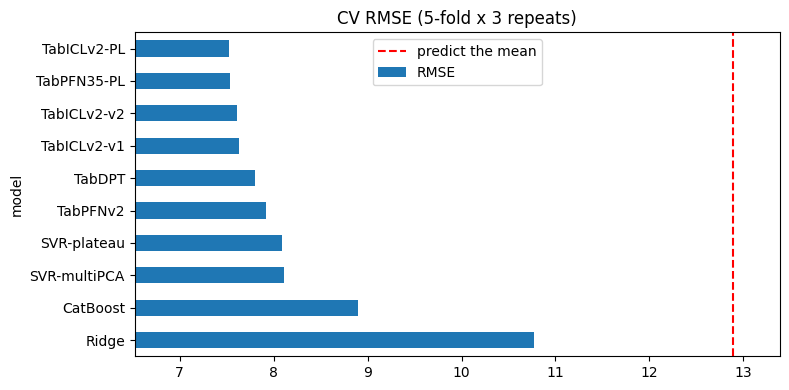

In [26]:
OOF, TEST, OOF_REP, rows = {}, {}, {}, []
for name, make in MODELS.items():
    t0 = time.time()
    score, OOF[name], TEST[name] = run_cv(make, X, X_te)
    OOF_REP[name] = run_cv.last_oof
    rows.append((name, score, np.mean(np.abs(y - OOF[name])), time.time() - t0))
    print(f'{name:13s} RMSE={score:.4f}  ({rows[-1][3]:.0f}s)')

OOF['FM-PL-mean'] = 0.5 * (OOF['TabICLv2-PL'] + OOF['TabPFN35-PL'])
TEST['FM-PL-mean'] = 0.5 * (TEST['TabICLv2-PL'] + TEST['TabPFN35-PL'])
print('residual corr TabICLv2-PL vs TabPFN35-PL:',
      round(np.corrcoef(y - OOF['TabICLv2-PL'], y - OOF['TabPFN35-PL'])[0, 1], 3))

cv_table = pd.DataFrame(rows, columns=['model', 'RMSE', 'MAE (bagged OOF)', 'seconds']).set_index('model')
cv_table = cv_table.sort_values('RMSE')
print()
print(cv_table.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
cv_table['RMSE'].plot.barh(ax=ax)
ax.axvline(y.std(), c='r', ls='--', label='predict the mean')
ax.set_xlim(cv_table['RMSE'].min() - 1, y.std() + 0.5)
ax.invert_yaxis()
ax.legend()
ax.set_title('CV RMSE (5-fold x 3 repeats)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'cv_leaderboard.png')
plt.show()

## Fine-Tuning TabICLv2

Fine-tuning adapts the pretrained weights to this dataset with a pinball loss and early stopping on an internal 10% split of the training fold, so the validation fold stays unseen. In theory it can lower bias; the risk is that the early-stopping split holds only about 30 rows. Fine-tuning at two learning rates is compared with the same zero-shot model on the first five folds.

In [27]:
ft_configs = {
    'zero-shot'  : lambda: TabICLRegressor(device=GPU_A, random_state=CFG.SEED, norm_methods=CFG.ICL_NORM),
    'ft lr=1e-5' : lambda: FinetunedTabICLRegressor(epochs=30, learning_rate=1e-5, device=GPU_A,
                                                    random_state=CFG.SEED, norm_methods=CFG.ICL_NORM),
    'ft lr=3e-6' : lambda: FinetunedTabICLRegressor(epochs=30, learning_rate=3e-6, device=GPU_A,
                                                    random_state=CFG.SEED, norm_methods=CFG.ICL_NORM),
}
ft_fold = {}
for name, make in ft_configs.items():
    ft_fold[name] = [rmse(y[vai], make().fit(X[tri], y[tri]).predict(X[vai])) for tri, vai in FOLDS[:5]]
ft_fold = pd.DataFrame(ft_fold)
print(ft_fold.round(3).to_string())
print('\nmean RMSE:', ft_fold.mean().round(4).to_dict())
for name in ['ft lr=1e-5', 'ft lr=3e-6']:
    d = ft_fold[name] - ft_fold['zero-shot']
    print(f'{name}: mean difference {d.mean():+.4f}, better on {(d < 0).sum()} of 5 folds')

   zero-shot  ft lr=1e-5  ft lr=3e-6
0      7.957       7.981       7.964
1      6.973       6.973       6.973
2      7.125       7.125       7.125
3      7.228       7.348       7.258
4      8.259       8.259       8.259

mean RMSE: {'zero-shot': 7.5084, 'ft lr=1e-5': 7.5372, 'ft lr=3e-6': 7.5156}
ft lr=1e-5: mean difference +0.0288, better on 0 of 5 folds
ft lr=3e-6: mean difference +0.0073, better on 0 of 5 folds


#### Insights

> Fine-tuning makes TabICLv2 worse. In the full local run on all 15 folds, a learning rate of 1e-5 raised the RMSE from 7.60 to 7.69 and was better on only 1 of 15 folds, a learning rate of 3e-6 raised it to 7.63, and freezing the column and row encoders still gave 7.65. The smaller the update, the closer the result is to zero-shot, which means the pretrained prior is better than anything the weights can learn from 382 rows. The final model uses zero-shot TabICLv2.

## Transductive Pseudo-Labelling

`TabICLv2-PL` receives the whole query set at prediction time: the validation fold during cross-validation and the 96 test rows at the end. It first predicts all query rows with the bagged TabICLv2, splits them into four parts, and predicts each part again with the other three parts and their pseudo labels added to the context. Three safeguards keep it honest. True labels of query rows are never used, a query row never sees its own pseudo label (otherwise the model would simply copy it), and the cross-validation reproduces the test situation closely, with a ratio of pseudo to labelled context rows of about 0.19 in both cases (58 of 306 per fold, 72 of 382 at test time). Using unlabeled test features this way is standard semi-supervised learning and does not use any test target or external data.

## TabPFN Checkpoint Zoo

Prior Labs publishes several gated regression checkpoints: TabPFN-2.5 (default, small-samples, real and low-skew variants), 2.6, 3 and 3.5 (September 2026). Each is scored as a plain in-context learner on the shared folds, and its residual correlation with the pseudo-labelled TabICLv2 shows whether it could add anything to the blend.

In [28]:
ZOO = {
    'TabPFN-2.5'        : 'tabpfn-v2.5-regressor-v2.5_default.ckpt',
    'TabPFN-2.5-small'  : 'tabpfn-v2.5-regressor-v2.5_small-samples.ckpt',
    'RealTabPFN-2.5'    : 'tabpfn-v2.5-regressor-v2.5_real.ckpt',
    'TabPFN-2.5-lowskew': 'tabpfn-v2.5-regressor-v2.5_low-skew.ckpt',
    'TabPFN-2.6'        : 'tabpfn-v2.6-regressor-v2.6_default.ckpt',
    'TabPFN-3'          : 'tabpfn-v3-regressor-v3_default.ckpt',
    'TabPFN-3.5'        : None,
}
zoo_rows = []
for name, ckpt in ZOO.items():
    if ckpt is None:
        make = lambda: TabPFNRegressor.create_default_for_version(ModelVersion.V3_5, device=GPU_B,
                                                                  n_estimators=8, random_state=CFG.SEED)
    else:
        make = lambda c=ckpt: TabPFNRegressor(model_path=c, device=GPU_B, n_estimators=8, random_state=CFG.SEED)
    score, oof_z, _ = run_cv(make, X)
    rc = np.corrcoef(y - oof_z, y - OOF['TabICLv2-PL'])[0, 1]
    zoo_rows.append((name, score, rc))
zoo = pd.DataFrame(zoo_rows, columns=['checkpoint', 'RMSE', 'residual corr vs TabICLv2-PL']).set_index('checkpoint')
print(zoo.sort_values('RMSE').round(4).to_string())

tabpfn-v2.5-regressor-v2.5_default.ckpt:   0%|          | 0.00/40.8M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

tabpfn-v2.5-regressor-v2.5_small-samples(…):   0%|          | 0.00/40.8M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

tabpfn-v2.5-regressor-v2.5_real.ckpt:   0%|          | 0.00/40.8M [00:00<?, ?B/s]

...

tabpfn-v2.6-regressor-v2.6_default.ckpt:   0%|          | 0.00/51.6M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

tabpfn-v3-regressor-v3_default.ckpt:   0%|          | 0.00/233M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/33.0 [00:00<?, ?B/s]

                      RMSE  residual corr vs TabICLv2-PL
checkpoint                                              
TabPFN-3.5          7.6607                        0.9813
TabPFN-3            7.7217                        0.9838
TabPFN-2.5-lowskew  7.7924                        0.9566
RealTabPFN-2.5      7.8309                        0.9608
TabPFN-2.6          7.8429                        0.9439
TabPFN-2.5          7.8465                        0.9548
TabPFN-2.5-small    7.8483                        0.9558


#### Insights

> Without pseudo-labelling, no TabPFN checkpoint beats TabICLv2. Locally, the 2.5 family scored about 7.79 to 7.88, version 2.6 about 7.84 and version 3 about 7.70, all with residual correlations of 0.94 to 0.98 against the pseudo-labelled TabICLv2, and none of them improved the version 3 blend. TabPFN-3.5 is the exception worth pursuing: at about 7.66 it is almost as accurate as TabICLv2, so it is also run with the same pseudo-labelling scheme as `TabPFN35-PL`.

## Kernel Choice from the Variogram

The foundation models all fail on the same rows, so the blend can only improve through its one member with different errors, the SVR. The target semivariogram rises roughly linearly from the origin, which in geostatistics indicates a rough process with an exponential covariance (Matern with smoothness 1/2), whereas the RBF kernel assumes an infinitely smooth function. If that reading is right, a Laplacian or Matern-1/2 kernel should beat the RBF kernel in the same SVR recipe.

In [29]:
def kernel_fn(name):
    if name == 'rbf':
        return lambda A, B: np.exp(-cdist(A, B, 'sqeuclidean') / A.shape[1])
    if name == 'laplacian':
        return lambda A, B: np.exp(-cdist(A, B, 'cityblock') / A.shape[1])
    if name == 'matern12':
        return lambda A, B: np.exp(-cdist(A, B) / np.sqrt(A.shape[1]))
    return lambda A, B: (1 + np.sqrt(3) * cdist(A, B) / np.sqrt(A.shape[1])) * np.exp(
        -np.sqrt(3) * cdist(A, B) / np.sqrt(A.shape[1]))


class KernelSVR:
    def __init__(self, kernel, C=10):
        self.K, self.C = kernel_fn(kernel), C

    def fit(self, A, t):
        self.A = A
        self.models = {k: log_target(z_target(SVR(kernel='precomputed', C=self.C, epsilon=0.05))).fit(
            self.K(views[k][0][A], views[k][0][A]), t) for k in PCA_DIMS}
        return self

    def predict(self, B):
        return np.mean([m.predict(self.K(views[k][0][B], views[k][0][self.A])) for k, m in self.models.items()], 0)


row_index = np.arange(len(y))
for kname in ['rbf', 'matern32', 'matern12', 'laplacian']:
    print(f'{kname:10s} CV RMSE={run_cv(lambda k=kname: KernelSVR(k), row_index)[0]:.4f}')

rbf        CV RMSE=8.0936
matern32   CV RMSE=8.0406
matern12   CV RMSE=8.5119
laplacian  CV RMSE=8.5361


#### Insights

> The rough kernels lose. Locally, the best Laplacian and Matern-1/2 settings scored about 8.51 and 8.35 against about 8.09 for RBF and 8.04 for Matern-3/2. The variogram was measured in the raw 24-dimensional space, where its apparent roughness is more likely target noise than a rough function, so the smooth RBF kernel is kept.

> Other model families were also tried locally as partners with different errors and rejected. Networks trained from scratch (RealMLP 8.82, TabM 9.94) and the learned-metric kernel machine xRFM (8.58) were both too inaccurate on about 300 rows and gave no blend gain, and weaker pseudo-labelled foundation models (TabDPT, TabPFN v2) made the foundation average worse.

## SVR Regularisation and Blend Value

A blend member is valuable for how different its errors are, not only for its own accuracy. The SVR penalty C controls how closely it follows the training targets, so a less regularised SVR may be slightly less accurate alone yet more independent of the foundation models. The SVR is refitted on a small grid of C and length-scale, and each setting is judged by the nested RMSE of its blend with the averaged pseudo-labelled foundation models.

In [30]:
def nested_pair(f, s_):
    scores = []
    for seed in [42, 7, 123, 2024, 99]:
        pr = np.zeros(len(y))
        for a, b in KFold(10, shuffle=True, random_state=seed).split(f):
            w, _ = nnls(np.c_[f[a], s_[a]], y[a])
            pr[b] = np.c_[f[b], s_[b]] @ (w / w.sum())
        scores.append(rmse(y, pr))
    return np.mean(scores)


svr_grid = []
for scale in [0.7, 1.0, 1.4]:
    for C in [3, 10, 30, 100]:
        score, oof_s, _ = run_cv(lambda sc=scale, c=C: MultiPCASVR(cells=[(sc, c)]), X)
        svr_grid.append((scale, C, score, np.corrcoef(y - oof_s, y - OOF['FM-PL-mean'])[0, 1],
                         nested_pair(OOF['FM-PL-mean'], oof_s)))
svr_grid = pd.DataFrame(svr_grid, columns=['length-scale', 'C', 'SVR RMSE', 'residual corr vs FM', 'blend RMSE'])
print(svr_grid.round(4).to_string(index=False))
print(f"\nplateau average (SVR-plateau) blend RMSE: {nested_pair(OOF['FM-PL-mean'], OOF['SVR-plateau']):.4f}"
      f"  | version 5 SVR (C=3): {nested_pair(OOF['FM-PL-mean'], OOF['SVR-multiPCA']):.4f}")

 length-scale   C  SVR RMSE  residual corr vs FM  blend RMSE
          0.7   3    8.2369               0.8611      7.3235
          0.7  10    8.0042               0.8598      7.2620
          0.7  30    8.3545               0.8194      7.2541
          0.7 100    8.8600               0.7772      7.2554
          1.0   3    8.1136               0.8645      7.2965
          1.0  10    8.0936               0.8529      7.2614
          1.0  30    8.3084               0.8283      7.2523
          1.0 100    8.7265               0.7988      7.2728
          1.4   3    8.2512               0.8577      7.3016
          1.4  10    8.2640               0.8475      7.2815
          1.4  30    8.4178               0.8309      7.2801
          1.4 100    8.9748               0.8030      7.3152

plateau average (SVR-plateau) blend RMSE: 7.2557  | version 5 SVR (C=3): 7.2965


#### Insights

> Blend value and single-model accuracy point in different directions. Raising C from 3 to 30 leaves the SVR's own RMSE about the same or slightly worse, but lowers its residual correlation with the foundation models and improves the blend. Locally the blend went from 7.296 at C=3 to between 7.252 and 7.262 for C of 10 or 30 and a length-scale multiplier of 0.7 or 1.0.

> Those four settings form a plateau rather than a single sharp optimum, so they are averaged instead of picking one, following the same rule used for the PCA dimensions. Locally the averaged SVR improved the version 5 blend in all three repeats (7.251 against 7.296 on the averaged out-of-fold predictions and 7.411 against 7.443 averaged over single repeats), with a paired bootstrap probability of about 0.84.

> One safeguard is added. A weakly regularised SVR on a log target can extrapolate far outside the possible range once its output is exponentiated. In the first version 6 run, single members predicted up to 138 for one test record, although the target never exceeds about 100.4, and cross-validation cannot validate such values because they almost never occur out-of-fold. Each member of `SVR-plateau` is therefore clipped to the range of its training targets before averaging. Locally this left the cross-validated blend unchanged (7.255 against 7.251) and changed two test predictions.

## Pseudo-Labelling the SVR

Pseudo-labelling helped the foundation models because the unlabeled query rows fill gaps in the labelled data. The SVR, now the blend member that moves the score, uses a local kernel and should benefit from the same densification. Its first-pass labels are the averaged pseudo-labelled foundation predictions for the query rows, taken from the same fold so that they come from models that never saw those rows' targets. The query rows are split into parts and each part is predicted with the other parts in the training set, so no row sees its own pseudo label. Splits of 2, 4 and 8 parts gave similar gains with no monotone trend, so the difference between them is noise from how the rows are partitioned, and the three are averaged.

In [31]:
def svr_with_pseudo(A, t, B, labels_B, splits=(2, 4, 8)):
    preds = []
    for n_split in splits:
        part = np.arange(len(B)) % n_split
        out = np.empty(len(B))
        for k in range(n_split):
            q, c = part == k, part != k
            out[q] = MultiPCASVR(cells=CFG.SVR_CELLS, clip=True).fit(
                np.vstack([A, B[c]]), np.r_[t, labels_B[c]]).predict(B[q])
        preds.append(out)
    return np.mean(preds, 0)


fm_rep = 0.5 * (OOF_REP['TabICLv2-PL'] + OOF_REP['TabPFN35-PL'])
svr_pl_rep = np.zeros((CFG.N_REPEATS, len(y)))
for i, (tri, vai) in enumerate(FOLDS):
    r = i // CFG.N_SPLITS
    svr_pl_rep[r, vai] = svr_with_pseudo(X[tri], y[tri], X[vai], fm_rep[r, vai])
OOF['SVR-plateau-PL'] = svr_pl_rep.mean(0)
TEST['SVR-plateau-PL'] = svr_with_pseudo(X, y, X_te, TEST['FM-PL-mean'])
OOF_REP['SVR-plateau-PL'] = svr_pl_rep

for name in ['SVR-plateau', 'SVR-plateau-PL']:
    own = np.mean([rmse(y, o) for o in OOF_REP[name]])
    rc = np.corrcoef(y - OOF[name], y - OOF['FM-PL-mean'])[0, 1]
    print(f"{name:15s} own RMSE={own:.4f}  residual corr vs FM={rc:.3f}  "
          f"blend with FM (nested)={nested_pair(OOF['FM-PL-mean'], OOF[name]):.4f}")

SVR-plateau     own RMSE=8.0907  residual corr vs FM=0.851  blend with FM (nested)=7.2557
SVR-plateau-PL  own RMSE=7.9014  residual corr vs FM=0.859  blend with FM (nested)=7.2330


#### Insights

> The pseudo-labelled SVR is more accurate on its own (locally about 7.90 to 7.92 against 8.09) while keeping almost the same residual correlation with the foundation models, so its blend value rises. Locally, averaging the 2-, 4- and 8-part splits improved the blend in all three repeats (by 0.046, 0.031 and 0.008), from 7.255 to 7.233 on the averaged out-of-fold predictions; the 4-part split alone had a paired bootstrap probability of about 0.94 of beating version 6. Using the version 6 blend instead of the foundation average as first-pass labels, or down-weighting the pseudo-labelled rows, gave slightly smaller gains.

## Pessimistic Cross-Check with Similarity Groups

Rows that lie within radius 1.0 of each other in standardised feature space are chained into groups and kept in the same fold. This is harsher than the real train-to-test situation, so the scores will rise, but the ranking of the models should not change if the choice is robust.

In [32]:
_, sim_groups = connected_components(
    NearestNeighbors(radius=1.0).fit(Z_tr).radius_neighbors_graph(Z_tr), directed=False)
for name in ['Ridge', 'CatBoost', 'SVR-multiPCA', 'TabICLv2-v1', 'TabICLv2-v2', 'TabICLv2-PL', 'TabPFN35-PL']:
    p = np.zeros(len(y))
    for tri, vai in GroupKFold(5).split(X, y, sim_groups):
        p[vai] = MODELS[name]().fit(X[tri], y[tri]).predict(X[vai])
    print(f'{name:13s} GroupKFold RMSE={rmse(y, p):.4f}  |  random KFold RMSE={cv_table.loc[name, "RMSE"]:.4f}')

Ridge         GroupKFold RMSE=11.2394  |  random KFold RMSE=10.7674
CatBoost      GroupKFold RMSE=9.6010  |  random KFold RMSE=8.8969
SVR-multiPCA  GroupKFold RMSE=8.6166  |  random KFold RMSE=8.1136
TabICLv2-v1   GroupKFold RMSE=7.9297  |  random KFold RMSE=7.6337
TabICLv2-v2   GroupKFold RMSE=7.8713  |  random KFold RMSE=7.6123
TabICLv2-PL   GroupKFold RMSE=7.9277  |  random KFold RMSE=7.5218
TabPFN35-PL   GroupKFold RMSE=7.8872  |  random KFold RMSE=7.5350


#### Insights

> Pseudo-labelling gives the largest single-model gain of the whole study. Locally, the pseudo-labelled TabICLv2 reached about 7.52 against 7.61 for the same four-seed TabICLv2 without it, and it was better on 12 of the 15 folds. A single model with a different random state (7.61) rules out a seed effect. Using half of the query rows as context gave 7.55 and three quarters gave 7.52, so more pseudo-labelled neighbours help.

> Among the other models, TabICLv2 remains the strongest at about 7.6, followed by TabDPT (about 7.8), TabPFN v2 (about 7.9), the SVR (about 8.1), CatBoost (about 8.9) and Ridge (about 10.8). The version 2 TabICLv2 is about 0.02 better than the version 1 configuration, a small but consistent gain.

> Under similarity-grouped folds every model gets worse, but the order is unchanged and the version 2 TabICLv2 keeps its lead over version 1 (about 7.90 against 7.95). The choice is not an artefact of near-duplicate rows leaking across folds.

---

# Ensemble, Selection Protocol and Limits <a name="7"></a>

---

A blend helps only when models make different mistakes. This section measures that, compares candidate blends with a protocol that does not rely on the public leaderboard, and then asks how close the chosen blend is to the limit of what the features can explain.

## Residual Correlation

Residuals are computed from the out-of-fold predictions of each model. A correlation near 1 means two models fail on the same rows and blending them adds little.

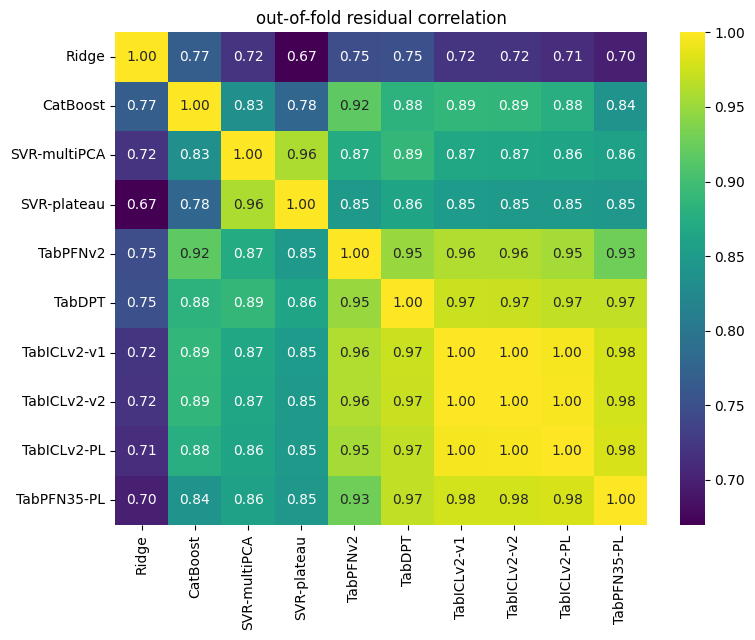

In [33]:
names = list(MODELS)
resid = pd.DataFrame({n: y - OOF[n] for n in names})
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(resid.corr(), annot=True, fmt='.2f', cmap='viridis', ax=ax)
ax.set_title('out-of-fold residual correlation')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'residual_corr.png')
plt.show()

#### Insights

> The three foundation models are pretrained on different data (two synthetic priors and one real-data corpus), yet their residuals correlate at about 0.96 to 0.97. They fail on the same rows, which points to a limit in the data rather than in any one model. The SVR is the only strong model with clearly different errors (about 0.84 against TabICLv2), because it sees a PCA view with a log target.

## Selection Protocol

Each candidate blend is fitted with non-negative least squares and judged on four criteria. The nested RMSE refits the weights inside a 10-fold split of the out-of-fold rows under five outer seeds. A paired bootstrap gives the probability that the candidate has a lower squared error than the version 6 blend (public 7.837). A leaderboard simulation draws random 29-row and 67-row subsets and counts how often the candidate beats version 6, which shows how much the public score can confirm. Finally, an adversarially weighted RMSE up-weights training rows that look like test rows. The best candidate replaces version 6 only if its nested RMSE is lower by more than 0.01 and the paired bootstrap gives it a probability above 0.9 of being better.

The two pseudo-labelled foundation models are almost collinear (residual correlation about 0.98). Free NNLS weights between them swing from fold to fold (locally between about 0.2 and 0.75), and that instability costs more than it gains. The standard remedy for nearly collinear predictors is to average them with equal weights and fit only the weight of the genuinely different SVR, which is the `FM-PL-mean` candidate.

In [34]:
def nnls_weights(P, t):
    w, _ = nnls(P, t)
    return w / w.sum()


def nested_blend(cols, seed):
    P = np.column_stack([OOF[c] for c in cols])
    out = np.zeros(len(y))
    for a, b in KFold(10, shuffle=True, random_state=seed).split(P):
        out[b] = P[b] @ nnls_weights(P[a], y[a])
    return out


p_test_like = cross_val_predict(LogisticRegression(C=0.3, max_iter=3000), X_all, is_test,
                                cv=skf, method='predict_proba')[:len(X), 1]
adv_w = p_test_like / (1 - p_test_like)
adv_w = adv_w / adv_w.mean()

CANDIDATES = {
    'v1: TabICL + SVR'           : ['TabICLv2-v1', 'SVR-multiPCA'],
    'v2: TabICL-bag + SVR'       : ['TabICLv2-v2', 'SVR-multiPCA'],
    'v3: TabICL-PL + SVR'        : ['TabICLv2-PL', 'SVR-multiPCA'],
    'v3 + TabICL-bag'            : ['TabICLv2-PL', 'TabICLv2-v2', 'SVR-multiPCA'],
    'v5: ICL-PL + PFN35-PL + SVR': ['TabICLv2-PL', 'TabPFN35-PL', 'SVR-multiPCA'],
    'v5: mean(ICL-PL, PFN35-PL) + SVR': ['FM-PL-mean', 'SVR-multiPCA'],
    'v6: mean(ICL-PL, PFN35-PL) + SVR-plateau': ['FM-PL-mean', 'SVR-plateau'],
    'v8: mean(ICL-PL, PFN35-PL) + SVR-plateau-PL': ['FM-PL-mean', 'SVR-plateau-PL'],
    'v2 + TabDPT'                : ['TabICLv2-v2', 'SVR-multiPCA', 'TabDPT'],
    'v2 + TabDPT + TabPFN'       : ['TabICLv2-v2', 'SVR-multiPCA', 'TabDPT', 'TabPFNv2'],
    'all models'                 : names,
}
BASELINE = 'v6: mean(ICL-PL, PFN35-PL) + SVR-plateau'
base_nested = nested_blend(CANDIDATES[BASELINE], CFG.SEED)
rng = np.random.default_rng(CFG.SEED)
sel_rows = []
for cname, cols in CANDIDATES.items():
    runs = [rmse(y, nested_blend(cols, s)) for s in [42, 7, 123, 2024, 99]]
    cand = nested_blend(cols, CFG.SEED)
    se_c, se_b = (y - cand) ** 2, (y - base_nested) ** 2
    boot = [np.mean((se_c - se_b)[rng.integers(0, len(y), len(y))]) for _ in range(4000)]
    win = lambda k: np.mean([se_c[i].mean() < se_b[i].mean()
                             for i in (rng.choice(len(y), k, replace=False) for _ in range(4000))])
    sel_rows.append((cname, np.mean(runs), np.std(runs), np.sqrt(np.mean(adv_w * se_c)),
                     np.mean(np.array(boot) < 0), win(29), win(67)))

selection = pd.DataFrame(sel_rows, columns=['candidate', 'nested RMSE', 'sd over seeds', 'adv-weighted RMSE',
                                            'P(better) bootstrap', 'P(win) public 29', 'P(win) private 67'])
print(selection.round(4).to_string(index=False))

best_row = selection.loc[selection['nested RMSE'].idxmin()]
base_score = selection.set_index('candidate').loc[BASELINE, 'nested RMSE']
adopt = (base_score - best_row['nested RMSE'] > 0.01) and (best_row['P(better) bootstrap'] > 0.9)
CHOSEN = best_row['candidate'] if adopt else BASELINE
print(f"\nbest: {best_row['candidate']} ({best_row['nested RMSE']:.4f}, P(better) "
      f"{best_row['P(better) bootstrap']:.3f}) vs baseline {base_score:.4f} -> adopt: {adopt}")
chosen_cols = CANDIDATES[CHOSEN]
P_oof  = np.column_stack([OOF[c] for c in chosen_cols])
P_test = np.column_stack([TEST[c] for c in chosen_cols])
weights = pd.Series(nnls_weights(P_oof, y), index=chosen_cols)
blend_oof = P_oof @ weights.values
nested = nested_blend(chosen_cols, CFG.SEED)
print(f'\nchosen: {CHOSEN}')
print(weights.round(3).to_string())

                                  candidate  nested RMSE  sd over seeds  adv-weighted RMSE  P(better) bootstrap  P(win) public 29  P(win) private 67
                           v1: TabICL + SVR       7.4107         0.0083             7.2536               0.0228            0.2740             0.2008
                       v2: TabICL-bag + SVR       7.3963         0.0072             7.2477               0.0262            0.2865             0.2055
                        v3: TabICL-PL + SVR       7.3156         0.0073             7.1706               0.1258            0.3757             0.3115
                            v3 + TabICL-bag       7.3156         0.0073             7.1706               0.1405            0.3850             0.3035
                v5: ICL-PL + PFN35-PL + SVR       7.3579         0.0140             7.2370               0.0025            0.2398             0.1202
           v5: mean(ICL-PL, PFN35-PL) + SVR       7.2965         0.0146             7.1656               0

#### Insights

> The equal-weight average of the two pseudo-labelled foundation models, blended with the SVR, is the version 5 candidate. Locally, on the same 15 folds, it improved the version 3 blend by about 0.02 to 0.025 RMSE (7.296 against 7.316 on the averaged out-of-fold predictions, and 7.443 against 7.468 averaged over single repeats), with a paired bootstrap probability of about 0.88 of being better. The same three models with free NNLS weights score worse than version 3 because of the weight instability described above, which is why the averaged form is used.

> Version 6 keeps that foundation average and replaces the SVR by the plateau-averaged, less regularised SVR. Locally this improved the nested RMSE in every repeat (7.251 against 7.296 on the averaged out-of-fold predictions), for a cumulative gain of about 0.065 over version 3.

> Even a gain of this size is hard to confirm on 29 public rows, as the public-size win probability shows, while the private-size probability is clearly higher. The decision is made on cross-validation.

> The adversarially weighted RMSE is lower than the plain RMSE for every candidate, which means the training rows that resemble the test set are, if anything, slightly easier. There is no sign that the test set is harder than the validation folds.

## Calibration: Is the Tail Really Under-Predicted?

Version 1 reported that rows with a true score above 70 are under-predicted by 13 to 20 points. Grouping by the true value is misleading, because even a perfect conditional-mean model shows that pattern (regression to the mean). The fair check groups rows by the prediction and asks whether the mean target in each group matches the mean prediction.

                  mean_pred  mean_y   n   gap
bin                                          
(34.191, 38.206]      36.73   35.53  39 -1.20
(38.206, 40.83]       39.47   39.04  38 -0.43
(40.83, 43.957]       42.31   41.66  38 -0.65
(43.957, 47.207]      45.45   45.00  38 -0.45
(47.207, 50.857]      48.79   48.68  38 -0.11
(50.857, 54.646]      52.76   51.63  38 -1.13
(54.646, 58.167]      56.32   57.37  38  1.04
(58.167, 60.844]      59.30   63.68  38  4.38
(60.844, 63.352]      61.88   61.66  38 -0.22
(63.352, 81.32]       68.01   67.77  39 -0.24

slope of y on nested blend = 1.075
nested RMSE without stretch = 7.2071 | with stretch = 7.2238


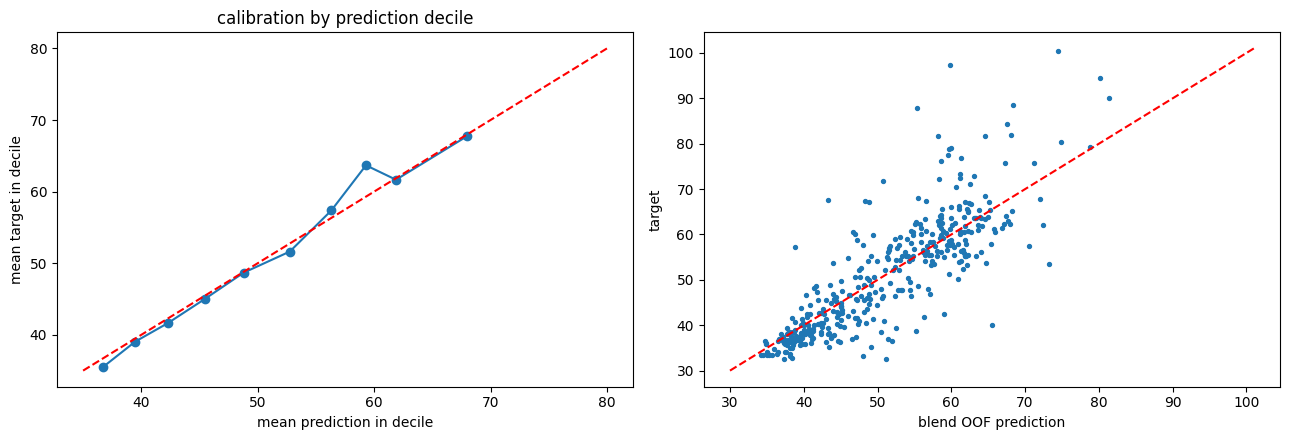

In [35]:
cal = pd.DataFrame({'pred': blend_oof, 'y': y})
cal['bin'] = pd.qcut(cal.pred, 10)
cal_tab = cal.groupby('bin', observed=True).agg(mean_pred=('pred', 'mean'), mean_y=('y', 'mean'), n=('y', 'size'))
cal_tab['gap'] = cal_tab.mean_y - cal_tab.mean_pred
print(cal_tab.round(2).to_string())

slope, intercept = np.polyfit(nested, y, 1)
stretched = np.zeros(len(y))
for a, b in KFold(10, shuffle=True, random_state=CFG.SEED).split(P_oof):
    w_a = nnls_weights(P_oof[a], y[a])
    stretched[b] = np.polyval(np.polyfit(P_oof[a] @ w_a, y[a], 1), P_oof[b] @ w_a)
print(f'\nslope of y on nested blend = {slope:.3f}')
print(f'nested RMSE without stretch = {rmse(y, nested):.4f} | with stretch = {rmse(y, stretched):.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(cal_tab.mean_pred, cal_tab.mean_y, 'o-')
ax[0].plot([35, 80], [35, 80], 'r--')
ax[0].set_xlabel('mean prediction in decile')
ax[0].set_ylabel('mean target in decile')
ax[0].set_title('calibration by prediction decile')
ax[1].scatter(blend_oof, y, s=8)
ax[1].plot([30, 101], [30, 101], 'r--')
ax[1].set_xlabel('blend OOF prediction')
ax[1].set_ylabel('target')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'calibration.png')
plt.show()

#### Insights

> The blend is well calibrated. In most prediction deciles the mean target is within about 1.5 to 2 points of the mean prediction, with no systematic drift, and the top decile is almost exact. The large under-prediction of true high scores reported in version 1 is regression to the mean, not a fixable bias, which is also why the linear stretch does not help. The high scores are rows that look like ordinary rows in feature space.

## How Close Is the Limit?

Two tests estimate how much signal is left. The first is a semivariogram borrowed from geostatistics. For every pair of training rows, half the squared difference of their targets is plotted against their feature distance. Its value at distance zero (the nugget) is the variance no smoother could remove, and the distance at which it reaches the blend's MSE shows the resolution the model effectively achieves. The second test fits three different learners to the blend's out-of-fold residuals. If none of them reaches a positive cross-validated R2, the remaining error has no structure these features can explain.

nugget (extrapolated to d=0) = 9.9  -> irreducible RMSE about 3.15
blend MSE = 51.8, reached by the variogram at distance about 1.05
median nearest-neighbour distance in train = 1.15
Ridge     CV R2 on blend residuals = -0.0091
kNN(15)   CV R2 on blend residuals = -0.1439
CatBoost  CV R2 on blend residuals = -0.0810


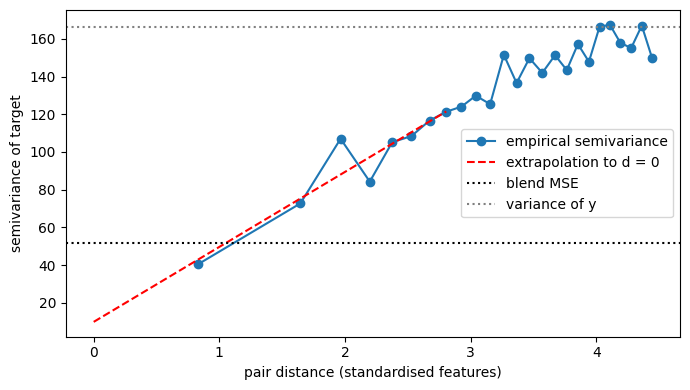

In [36]:
d_pair = pdist(Z_tr)
g_pair = 0.5 * pdist(y[:, None], 'sqeuclidean')
edges = np.quantile(d_pair, np.linspace(0, 0.25, 26))
mid = 0.5 * (edges[1:] + edges[:-1])
gam = np.array([g_pair[(d_pair >= lo) & (d_pair < hi)].mean() for lo, hi in zip(edges[:-1], edges[1:])])
coef = np.polyfit(mid[:8], gam[:8], 1)
mse_blend = rmse(y, blend_oof) ** 2
print(f'nugget (extrapolated to d=0) = {max(coef[1], 0):.1f}  -> irreducible RMSE about {np.sqrt(max(coef[1], 0)):.2f}')
print(f'blend MSE = {mse_blend:.1f}, reached by the variogram at distance about {(mse_blend - coef[1]) / coef[0]:.2f}')
print(f'median nearest-neighbour distance in train = {np.median(d_trtr):.2f}')

res_blend = y - blend_oof
cv10 = KFold(10, shuffle=True, random_state=CFG.SEED)
res_learners = {
    'Ridge'   : make_pipeline(StandardScaler(), RidgeCV(np.logspace(-2, 4, 30))),
    'kNN(15)' : make_pipeline(StandardScaler(), KNeighborsRegressor(15)),
    'CatBoost': CatBoostRegressor(iterations=400, learning_rate=0.02, depth=3, l2_leaf_reg=10,
                                  verbose=0, random_seed=CFG.SEED, allow_writing_files=False),
}
for name, m in res_learners.items():
    p = cross_val_predict(m, np.hstack([X, blend_oof[:, None]]), res_blend, cv=cv10)
    print(f'{name:9s} CV R2 on blend residuals = {1 - np.mean((res_blend - p) ** 2) / np.var(res_blend):+.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mid, gam, 'o-', label='empirical semivariance')
xx = np.linspace(0, mid[7], 20)
ax.plot(xx, np.polyval(coef, xx), 'r--', label='extrapolation to d = 0')
ax.axhline(mse_blend, c='k', ls=':', label='blend MSE')
ax.axhline(y.var(), c='gray', ls=':', label='variance of y')
ax.set_xlabel('pair distance (standardised features)')
ax.set_ylabel('semivariance of target')
ax.legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'variogram.png')
plt.show()

#### Insights

> No learner finds structure in the residuals. All three reach a cross-validated R2 at or below zero, even when they are given the blend prediction as an input, so the information these features carry about the score is used up.

> The variogram explains why. Its extrapolated nugget is small (an irreducible RMSE of roughly 3), so the target itself is not very noisy, but the blend's MSE is reached at a pair distance of about 1, which is the typical nearest-neighbour distance in this dataset. The model is about as accurate as knowing the score of the nearest training record. The remaining error comes from how sparsely 382 rows cover a 24-dimensional space, and more data, not a different model, would be needed to go further.

## Why Pseudo-Labelling Helps

The variogram says the error is limited by how far each record is from its nearest labelled neighbour. If pseudo-labelling works by filling those gaps, its gain should be near zero for records that already have a close training neighbour and largest for records that do not. The reduction in squared error is grouped by the distance from each validation row to its nearest training row in the first repeat.

                 mean  count
bin                         
(0.202, 0.798]  0.021     96
(0.798, 1.205]  1.073     95
(1.205, 1.767]  3.350     95
(1.767, 5.631]  1.293     96


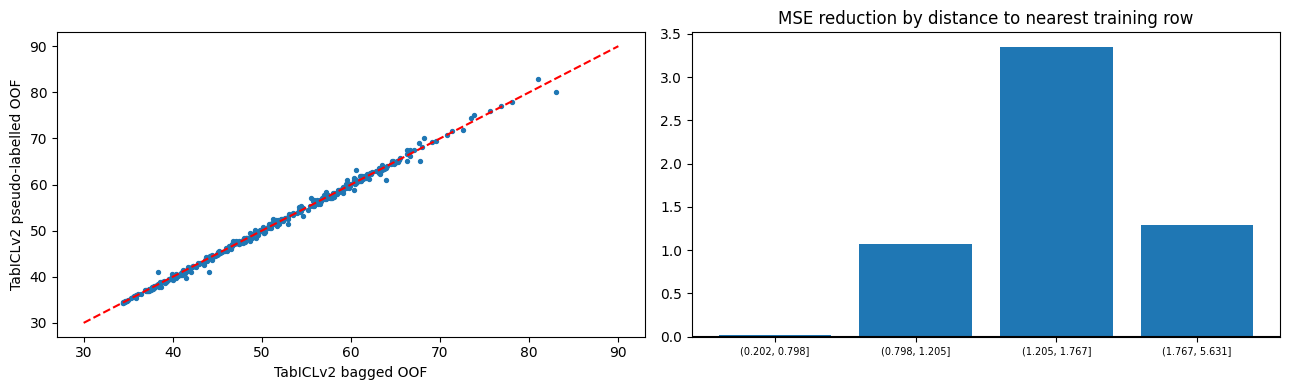

In [37]:
d_nearest = np.zeros(len(y))
for tri, vai in FOLDS[:CFG.N_SPLITS]:
    d_nearest[vai] = NearestNeighbors(n_neighbors=1).fit(Z_tr[tri]).kneighbors(Z_tr[vai])[0][:, 0]
pl_gain = pd.DataFrame({'distance': d_nearest,
                        'mse_reduction': (y - OOF['TabICLv2-v2']) ** 2 - (y - OOF['TabICLv2-PL']) ** 2})
pl_gain['bin'] = pd.qcut(pl_gain.distance, 4)
by_dist = pl_gain.groupby('bin', observed=True).mse_reduction.agg(['mean', 'count'])
print(by_dist.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(OOF['TabICLv2-v2'], OOF['TabICLv2-PL'], s=8)
ax[0].plot([30, 90], [30, 90], 'r--')
ax[0].set_xlabel('TabICLv2 bagged OOF')
ax[0].set_ylabel('TabICLv2 pseudo-labelled OOF')
ax[1].bar(range(len(by_dist)), by_dist['mean'])
ax[1].set_xticks(range(len(by_dist)), [str(i) for i in by_dist.index], fontsize=7)
ax[1].axhline(0, c='k')
ax[1].set_title('MSE reduction by distance to nearest training row')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'pseudo_label_gain.png')
plt.show()

#### Insights

> The gain follows the density argument. In the full local run, rows whose nearest training neighbour is closer than about 0.8 gained the least (about 0.02 in squared error), while rows between about 1.2 and 1.8 from the nearest training row gained the most (about 3.4). Pseudo-labelled test rows act as extra, slightly noisy neighbours exactly where the labelled data is sparse, which is the limit version 2 identified. It is not a leak and not a seed effect, and it is the one lever in this study that attacks that limit directly.

## Which Validation Scheme Looks Like the Test Set?

The pseudo-labelled TabICLv2 wins under random K-fold but loses under the similarity-grouped folds. Pseudo-labelling can fail when the query rows are far from labelled data and clustered together, because their first-pass errors are then correlated and feeding them back reinforces them. Both conditions can be measured from the features alone: the distance from each query row to its nearest labelled row, and to its nearest other query row. The test set is compared with the validation folds of both schemes using the two-sample Kolmogorov-Smirnov statistic.

test          median distance to labelled=1.242  to other query=1.832  | KS vs test: 0.000 / 0.000
random folds  median distance to labelled=1.205  to other query=1.807  | KS vs test: 0.079 / 0.072
group folds   median distance to labelled=1.456  to other query=1.379  | KS vs test: 0.385 / 0.294


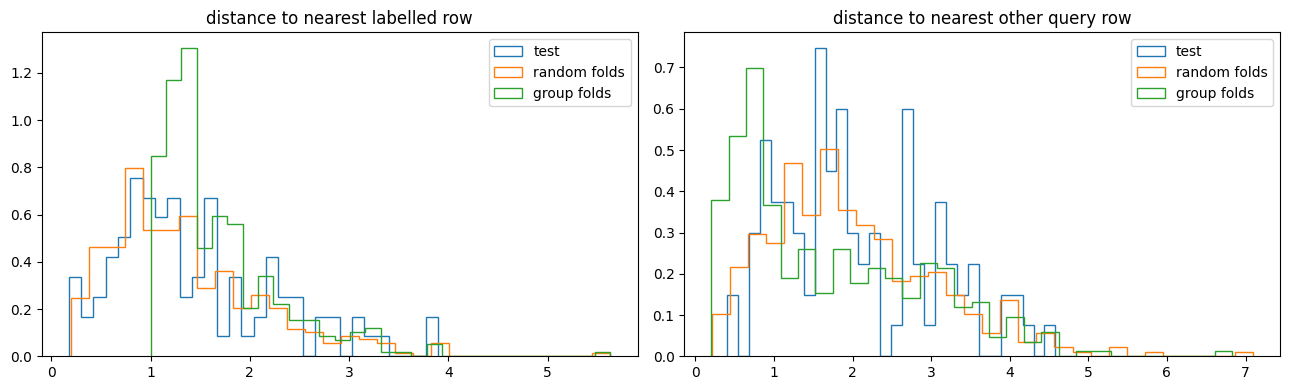

In [38]:
GROUP_FOLDS = list(GroupKFold(5).split(X, y, sim_groups))


def query_geometry(Z_lab, Z_q):
    d_lab = NearestNeighbors(n_neighbors=1).fit(Z_lab).kneighbors(Z_q)[0][:, 0]
    d_pool = NearestNeighbors(n_neighbors=2).fit(Z_q).kneighbors(Z_q)[0][:, 1]
    return d_lab, d_pool


geo = {'test': query_geometry(Z_tr, Z_te)}
for name, folds in [('random folds', FOLDS[:CFG.N_SPLITS]), ('group folds', GROUP_FOLDS)]:
    parts = [query_geometry(Z_tr[tri], Z_tr[vai]) for tri, vai in folds]
    geo[name] = (np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts]))
for name, (d_lab, d_pool) in geo.items():
    ks_lab = stats.ks_2samp(d_lab, geo['test'][0]).statistic
    ks_pool = stats.ks_2samp(d_pool, geo['test'][1]).statistic
    print(f'{name:13s} median distance to labelled={np.median(d_lab):.3f}  to other query={np.median(d_pool):.3f}'
          f'  | KS vs test: {ks_lab:.3f} / {ks_pool:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, (d_lab, d_pool) in geo.items():
    ax[0].hist(d_lab, bins=30, density=True, histtype='step', lw=2, label=name)
    ax[1].hist(d_pool, bins=30, density=True, histtype='step', lw=2, label=name)
ax[0].set_title('distance to nearest labelled row')
ax[1].set_title('distance to nearest other query row')
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'test_geometry.png')
plt.show()

#### Insights

> The test set matches the random folds almost exactly (KS statistics of about 0.08 and 0.07) and differs strongly from the grouped folds (about 0.39 and 0.30). By construction, no grouped validation row lies within distance 1 of a labelled row, and the grouped query rows sit close to each other, which is exactly the failure setting for pseudo-labelling. The test rows do not look like that, so the grouped result is a stress test that does not describe the test set, and the random-fold gain is the relevant estimate.

## Does the Gain Shrink With More Labelled Data?

In cross-validation the labelled context has about 306 rows, while the final model uses 382. If pseudo-labelling mainly helps when labelled data is scarce, its gain could be smaller at test time than cross-validation suggests. Plain and pseudo-labelled TabICLv2 are compared at several labelled sizes n, keeping the ratio of pseudo to labelled context rows at its test-time value by using n/4 query rows. Two random states per model keep the runtime moderate.

 n_labelled   plain  pseudo-label  folds PL better    gain
        120 10.0111       10.0338           0.4000 -0.0227
        180  8.4663        8.3998           0.6667  0.0665
        240  8.1364        8.0194           0.7333  0.1170
        306  7.6146        7.5330           0.6000  0.0816


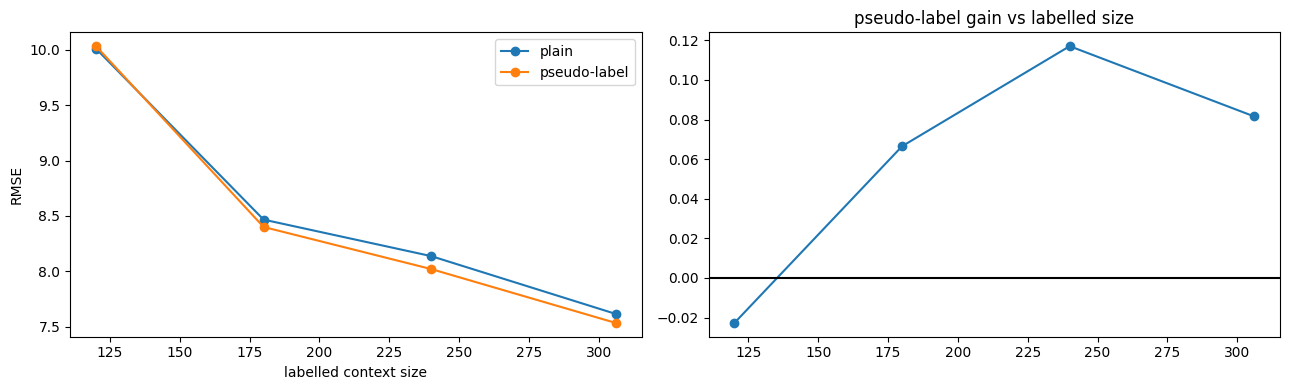

In [39]:
LC_SEEDS = [0, 1]
lc_rng = np.random.default_rng(CFG.SEED)
lc_rows = []
for n_lab in [120, 180, 240, 306]:
    e_plain, e_pl = [], []
    for tri, vai in FOLDS:
        tri_n = lc_rng.choice(tri, n_lab, replace=False) if n_lab < len(tri) else tri
        vai_q = lc_rng.choice(vai, min(n_lab // 4, len(vai)), replace=False)
        p_plain = BaggedTabICL(LC_SEEDS, GPU_A, norm_methods=CFG.ICL_NORM).fit(X[tri_n], y[tri_n]).predict(X[vai_q])
        p_pl = PseudoLabelTabICL(seeds=LC_SEEDS, device=GPU_A).fit(X[tri_n], y[tri_n]).predict(X[vai_q])
        e_plain.append(np.mean((y[vai_q] - p_plain) ** 2))
        e_pl.append(np.mean((y[vai_q] - p_pl) ** 2))
    better = np.mean(np.sqrt(e_pl) < np.sqrt(e_plain))
    lc_rows.append((n_lab, np.sqrt(np.mean(e_plain)), np.sqrt(np.mean(e_pl)), better))
lc = pd.DataFrame(lc_rows, columns=['n_labelled', 'plain', 'pseudo-label', 'folds PL better'])
lc['gain'] = lc['plain'] - lc['pseudo-label']
print(lc.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(lc.n_labelled, lc.plain, 'o-', label='plain')
ax[0].plot(lc.n_labelled, lc['pseudo-label'], 'o-', label='pseudo-label')
ax[0].set_xlabel('labelled context size')
ax[0].set_ylabel('RMSE')
ax[0].legend()
ax[1].plot(lc.n_labelled, lc.gain, 'o-')
ax[1].axhline(0, c='k')
ax[1].set_title('pseudo-label gain vs labelled size')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'learning_curve.png')
plt.show()

#### Insights

> The gain does not shrink with more labelled data. In the local run it was slightly negative at 120 labelled rows (-0.02), then +0.07, +0.12 and +0.08 at 180, 240 and 306 rows. Pseudo-labelling needs a first pass that is accurate enough to be worth copying, and above about 180 labelled rows it is. At 382 rows the gain should be at least as large as in cross-validation, so the cross-validation estimate is not optimistic for this reason. The version 3 public score moved less than cross-validation predicted (7.902 to 7.888), which is within the noise of 29 rows.

## Can Uncertainty Filtering Make Pseudo-Labelling Robust?

A standard remedy for confirmation bias is to pseudo-label only the rows the model is confident about. TabICLv2 returns predictive quantiles, so the inter-quartile range is a per-row uncertainty. The most certain fraction of the query rows is kept as context, and every variant is scored under both validation schemes with two random states.

In [40]:
class FilteredPseudoLabelTabICL(PseudoLabelTabICL):
    def __init__(self, keep, **kw):
        super().__init__(**kw)
        self.keep = keep

    def predict(self, B):
        outs = [TabICLRegressor(device=self.device, random_state=s, norm_methods=CFG.ICL_NORM).fit(self.A, self.t)
                .predict(B, output_type=['mean', 'quantiles'], alphas=[0.25, 0.75]) for s in self.seeds]
        first = np.mean([o['mean'] for o in outs], 0)
        iqr = np.mean([np.asarray(o['quantiles'])[:, 1] - np.asarray(o['quantiles'])[:, 0] for o in outs], 0)
        confident = iqr <= np.quantile(iqr, self.keep)
        part = np.arange(len(B)) % self.n_split
        out = np.empty(len(B))
        for k in range(self.n_split):
            q, c = part == k, (part != k) & confident
            out[q] = self._bag(np.vstack([self.A, B[c]]), np.r_[self.t, first[c]], B[q])
        return out


def cv_scheme(make, folds):
    n_rep = len(folds) // CFG.N_SPLITS
    oof = np.zeros((n_rep, len(y)))
    for i, (tri, vai) in enumerate(folds):
        oof[i // CFG.N_SPLITS, vai] = make().fit(X[tri], y[tri]).predict(X[vai])
    return np.mean([rmse(y, o) for o in oof])


robust_cfg = {
    'plain'       : lambda: BaggedTabICL(LC_SEEDS, GPU_A, norm_methods=CFG.ICL_NORM),
    'PL keep=1.0' : lambda: PseudoLabelTabICL(seeds=LC_SEEDS, device=GPU_A),
    'PL keep=0.75': lambda: FilteredPseudoLabelTabICL(0.75, seeds=LC_SEEDS, device=GPU_A),
    'PL keep=0.5' : lambda: FilteredPseudoLabelTabICL(0.5, seeds=LC_SEEDS, device=GPU_A),
}
robust = pd.DataFrame({
    name: {'random folds': cv_scheme(make, FOLDS), 'group folds': cv_scheme(make, GROUP_FOLDS)}
    for name, make in robust_cfg.items()
}).T
robust['gain random'] = robust.loc['plain', 'random folds'] - robust['random folds']
robust['gain group'] = robust.loc['plain', 'group folds'] - robust['group folds']
print(robust.round(4).to_string())

              random folds  group folds  gain random  gain group
plain               7.6106       7.8727       0.0000      0.0000
PL keep=1.0         7.5154       7.9220       0.0951     -0.0493
PL keep=0.75        7.5502       7.8355       0.0603      0.0372
PL keep=0.5         7.5844       7.7629       0.0261      0.1098


#### Insights

> Filtering moves the result along a single trade-off line instead of fixing it. Locally, keeping all pseudo labels gained about 0.10 under random folds and lost about 0.12 under grouped folds, keeping 75% gained 0.06 and lost 0.03, and keeping 50% gained 0.03 and lost almost nothing. The uncertainty signal is real (the IQR correlates with the error at about 0.31), but removing pseudo rows also removes the extra neighbours that produce the gain.

> Because the test geometry matches the random folds, the full pseudo-labelling configuration is kept. Two further extensions were tested locally and also rejected, since both changed the nested blend RMSE by less than the spread over seeds: training the SVR on the pseudo-labelled rows as well (-0.005) and a second pseudo-labelling round (-0.006).

## How Much to Trust the Public Leaderboard

The public leaderboard uses about 30% of the 96 test rows, roughly 29 records. Resampling 29 out-of-fold residuals many times shows how much the public score can move by chance alone.

OOF RMSE 7.198
public (29 rows)  90% range: 4.67 to 9.82
private (67 rows) 90% range: 5.52 to 8.81


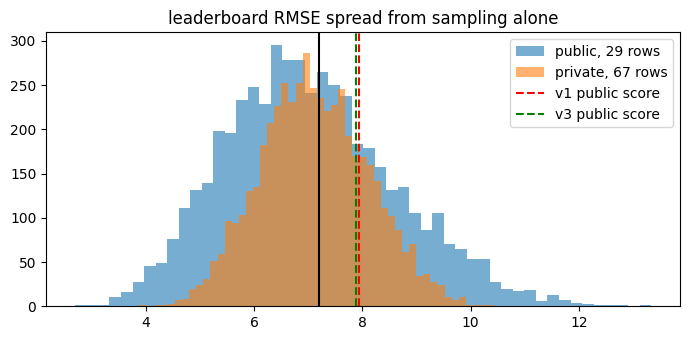

In [41]:
pub = [np.sqrt(np.mean(rng.choice(res_blend, 29, replace=False) ** 2)) for _ in range(5000)]
prv = [np.sqrt(np.mean(rng.choice(res_blend, 67, replace=False) ** 2)) for _ in range(5000)]
print(f'OOF RMSE {rmse(y, blend_oof):.3f}')
print(f'public (29 rows)  90% range: {np.percentile(pub, 5):.2f} to {np.percentile(pub, 95):.2f}')
print(f'private (67 rows) 90% range: {np.percentile(prv, 5):.2f} to {np.percentile(prv, 95):.2f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(pub, bins=50, alpha=0.6, label='public, 29 rows')
ax.hist(prv, bins=50, alpha=0.6, label='private, 67 rows')
ax.axvline(rmse(y, blend_oof), c='k')
ax.axvline(7.947, c='r', ls='--', label='v1 public score')
ax.axvline(7.888, c='g', ls='--', label='v3 public score')
ax.legend()
ax.set_title('leaderboard RMSE spread from sampling alone')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'lb_noise.png')
plt.show()

#### Insights

> The same model can score anywhere from about 4.7 to 9.9 on the public leaderboard purely from which 29 rows are public. The version 1 public score of 7.947 sits well inside that range, so it is consistent with the cross-validation estimate and says nothing about overfitting either way.

> Model selection is therefore done by cross-validation on 382 rows. The public leaderboard is used only to check that the file is valid and the score is inside the expected range. Tuning toward the public score would fit the noise of 29 rows.

---

# Row-Order Information <a name="8"></a>

---

An audit of the provided files found that the rows of `train.csv` are almost sorted by the target. Earlier checks only tested the numbers inside `record_id`, which are shuffled, and missed the position of each row in the file. In direct communication with the team on 4 October 2026, the organisers confirmed that using the row order of the provided files is part of each participant's EDA and preprocessing. This section measures the order signal in both files, validates ways of using it with a simulation that mimics a separate test file, and builds the final prediction from it.

## Row Order in the Provided Files

The target of the training rows is compared with their position in the file. The test file has no target, so its order is checked indirectly: if it is sorted the same way, the feature-only predictions should also fall along the file, and each feature should drift along the test file in the same direction as along the training file.

train: Spearman(row position, target)              = -0.981
train: Spearman(row position, feature OOF prediction) = -0.846
test : Spearman(row position, feature prediction)     = -0.806
correlation of per-feature drift along the file, train vs test = 0.873


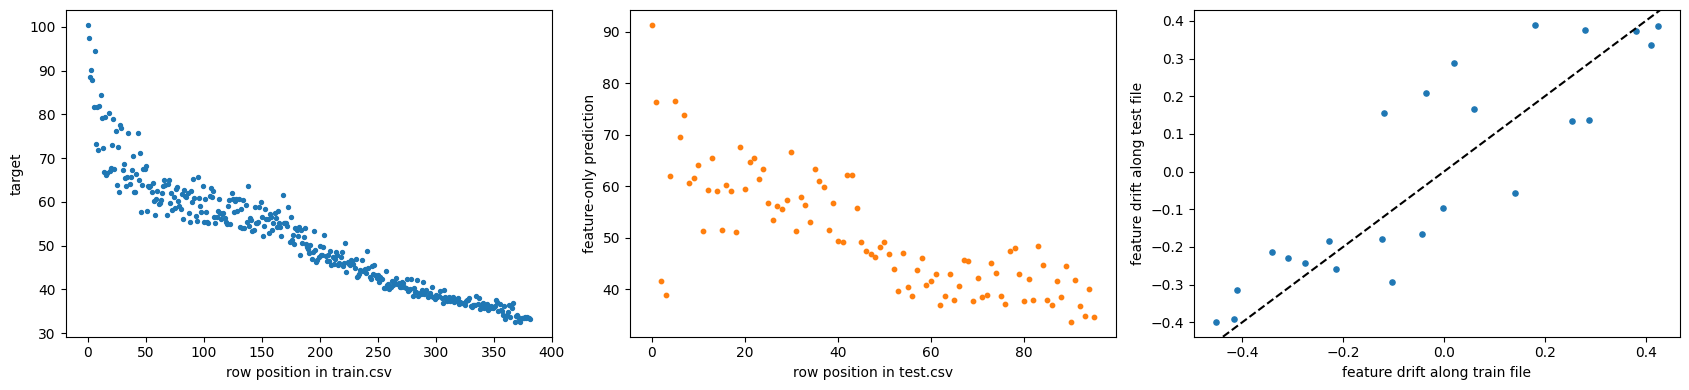

In [42]:
pos_tr = np.arange(len(y))
pos_te = np.arange(len(X_te))
ORDER_FEATURE_COLS = ['FM-PL-mean', 'SVR-plateau-PL']
FEAT_W = np.array([0.7, 0.3])
feat_test = np.column_stack([TEST[c] for c in ORDER_FEATURE_COLS]) @ FEAT_W
rho_train = stats.spearmanr(pos_tr, y).statistic
rho_oof = stats.spearmanr(pos_tr, nested).statistic
rho_test = stats.spearmanr(pos_te, feat_test).statistic
drift_tr = np.array([stats.spearmanr(pos_tr, X[:, j]).statistic for j in range(X.shape[1])])
drift_te = np.array([stats.spearmanr(pos_te, X_te[:, j]).statistic for j in range(X.shape[1])])
print(f'train: Spearman(row position, target)              = {rho_train:+.3f}')
print(f'train: Spearman(row position, feature OOF prediction) = {rho_oof:+.3f}')
print(f'test : Spearman(row position, feature prediction)     = {rho_test:+.3f}')
print(f'correlation of per-feature drift along the file, train vs test = {np.corrcoef(drift_tr, drift_te)[0, 1]:.3f}')
assert rho_test < -0.5, 'the test file does not look sorted in the same direction as the training file'

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].scatter(pos_tr, y, s=8)
ax[0].set_xlabel('row position in train.csv')
ax[0].set_ylabel('target')
ax[1].scatter(pos_te, feat_test, s=10, c='tab:orange')
ax[1].set_xlabel('row position in test.csv')
ax[1].set_ylabel('feature-only prediction')
ax[2].scatter(drift_tr, drift_te, s=14)
ax[2].axline((0, 0), slope=1, c='k', ls='--')
ax[2].set_xlabel('feature drift along train file')
ax[2].set_ylabel('feature drift along test file')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'row_order.png')
plt.show()

#### Insights

> The training rows are sorted by the target in decreasing order, with small local disorder. In a local audit the rank correlation between row position and target was about -0.98. The feature-only predictions for the test file also fall strongly along the file and the per-feature drifts agree between the two files. This is strong indirect evidence, not proof, that the test file was sorted the same way: the test targets are unknown. The assertion only stops the notebook if the evidence points the other way.

## Order-Preserving Validation on the Cross-Validation Folds

A test file only reveals the order of its own rows. The validation reproduces that on the 15 folds of Section 4: the original file order is kept inside each training part and each validation fold, and positions are normalised within each of them. Four candidates are built per validation fold: the quantile map (target of the training part at the same relative position), the isotonic projection of the feature predictions onto a decreasing sequence, the feature predictions sorted to the file order, and the raw feature predictions, which are not monotone.

To keep the estimate free of label leakage, nothing is fitted on the folds being evaluated. The two feature-blend weights are fixed in advance at 0.7 and 0.3 (rounded from earlier rounds) and always applied to the version 8 pair (pseudo-labelled foundation mean and pseudo-labelled SVR), independent of the automatic selection in Section 7, so the feature predictions of a validation fold come only from models trained on its training part, and the candidates are combined by a short list of averaging rules fixed in advance instead of fitted weights. Fitting combination weights on the other folds would leak, because those folds' quantile maps and feature models are built from the targets of the fold under evaluation.

                                mean    10%    50%    90%
quantile map                   3.648  3.007  3.448  4.480
isotonic features              5.423  4.610  5.432  6.177
sorted features                4.359  3.606  4.419  4.935
raw features                   7.322  6.538  7.429  7.941
mean(quantile, isotonic)       3.865  3.101  3.807  4.634
mean(quantile, sorted)         3.613  2.852  3.435  4.308
mean(quantile, isotonic, raw)  4.563  3.851  4.709  5.315

chosen rule: mean(quantile, sorted) (lowest mean fold RMSE among 7 pre-specified rules)
29-row subsets of the chosen rule: median RMSE 3.382, 10-90% 2.503 to 4.867


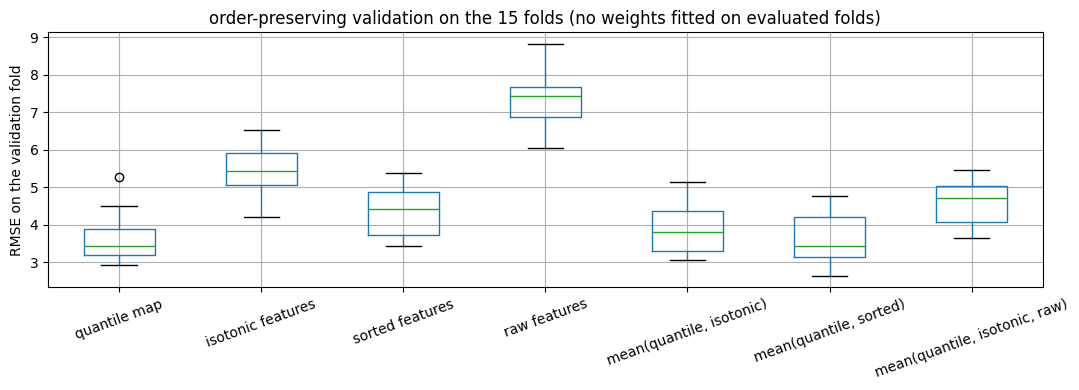

In [43]:
def unit_rank(n):
    return (np.arange(n) + 0.5) / n


def order_candidates(y_ref, f_query):
    q_ref, q_query = unit_rank(len(y_ref)), unit_rank(len(f_query))
    quantile_map = IsotonicRegression(increasing=False, out_of_bounds='clip').fit(q_ref, y_ref).predict(q_query)
    isotonic_features = IsotonicRegression(increasing=False).fit(q_query, f_query).predict(q_query)
    sorted_features = np.sort(f_query)[::-1]
    return np.c_[quantile_map, isotonic_features, sorted_features, f_query]


ORDER_RULES = {
    'quantile map'                 : [1, 0, 0, 0],
    'isotonic features'            : [0, 1, 0, 0],
    'sorted features'              : [0, 0, 1, 0],
    'raw features'                 : [0, 0, 0, 1],
    'mean(quantile, isotonic)'     : [1 / 2, 1 / 2, 0, 0],
    'mean(quantile, sorted)'       : [1 / 2, 0, 1 / 2, 0],
    'mean(quantile, isotonic, raw)': [1 / 3, 1 / 3, 0, 1 / 3],
}


def member_rep(c):
    if c == 'FM-PL-mean':
        return 0.5 * (OOF_REP['TabICLv2-PL'] + OOF_REP['TabPFN35-PL'])
    return OOF_REP[c]


M_rep = np.stack([member_rep(c) for c in ORDER_FEATURE_COLS], axis=-1)
rows_sim, fold_err = [], {k: [] for k in ORDER_RULES}
for i, (tri, vai) in enumerate(FOLDS):
    r = i // CFG.N_SPLITS
    tri, vai = np.sort(tri), np.sort(vai)
    P = order_candidates(y[tri], M_rep[r][vai] @ FEAT_W)
    row = []
    for name, w in ORDER_RULES.items():
        p = P @ np.array(w, dtype=float)
        fold_err[name].append((y[vai] - p) ** 2)
        row.append(rmse(y[vai], p))
    rows_sim.append(row)
sim_tab = pd.DataFrame(rows_sim, columns=list(ORDER_RULES))
print(sim_tab.describe(percentiles=[0.1, 0.5, 0.9]).T[['mean', '10%', '50%', '90%']].round(3).to_string())

ORDER_RULE = sim_tab.mean().idxmin()
ORDER_WEIGHTS = np.array(ORDER_RULES[ORDER_RULE], dtype=float)
print(f'\nchosen rule: {ORDER_RULE} (lowest mean fold RMSE among {len(ORDER_RULES)} pre-specified rules)')

sim_rng = np.random.default_rng(CFG.SEED)
public_like = [np.sqrt(e2[sim_rng.choice(len(e2), 29, replace=False)].mean())
               for e2 in fold_err[ORDER_RULE] for _ in range(200)]
print(f'29-row subsets of the chosen rule: median RMSE {np.median(public_like):.3f}, '
      f'10-90% {np.percentile(public_like, 10):.3f} to {np.percentile(public_like, 90):.3f}')

fig, ax = plt.subplots(figsize=(11, 4))
sim_tab.boxplot(ax=ax, rot=20)
ax.set_ylabel('RMSE on the validation fold')
ax.set_title('order-preserving validation on the 15 folds (no weights fitted on evaluated folds)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'order_simulation.png')
plt.show()

#### Insights

> Each column is a fixed rule, so its fold scores are not inflated by weights fitted on the evaluated fold. A local audit of the quantile map alone in a similar simulation gave a median of about 4.0, against about 7 for the features alone, so the order is expected to dominate and the averaging rules test whether the feature predictions add anything on top of it.

> Three limits remain and are stated rather than hidden. Choosing the best of seven rules on the same folds adds selection optimism of unknown size to the winning column. The fixed feature weights 0.7 and 0.3 were themselves rounded from earlier full-data fits. And the validation assumes the test file was cut from the sorted data like a random subset of rows, which cannot be checked without the test targets.

## Applying the Order Model to the Test File

The three order-based predictions are computed for the test file from its own row order, using all training rows for the quantile map and the version 8 feature predictions (fixed weights 0.7 and 0.3) for the others, and combined with the rule chosen above.

order-based prediction: mean 50.76, range 33.50 to 92.37
agreement with the feature-only prediction: corr=0.816, RMS difference=7.063


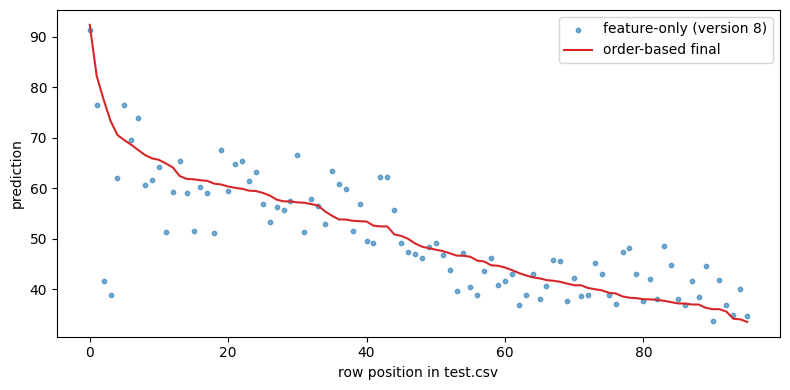

In [44]:
P_order_test = order_candidates(y, feat_test)
order_pred = P_order_test @ ORDER_WEIGHTS
print(f'order-based prediction: mean {order_pred.mean():.2f}, range {order_pred.min():.2f} to {order_pred.max():.2f}')
print(f'agreement with the feature-only prediction: corr={np.corrcoef(order_pred, feat_test)[0, 1]:.3f}, '
      f'RMS difference={rmse(order_pred, feat_test):.3f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(pos_te, feat_test, s=10, alpha=0.6, label='feature-only (version 8)')
ax.plot(pos_te, order_pred, c='tab:red', label='order-based final')
ax.set_xlabel('row position in test.csv')
ax.set_ylabel('prediction')
ax.legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'order_test_prediction.png')
plt.show()

#### Insights

> The final prediction follows the file order, with the feature models deciding where inside the allowed band each row sits. The plot shows how much the order moves each feature-only prediction; rows where the two disagree most are the ones whose features look ordinary but whose position marks them as extreme, which is exactly the tail that the feature models could never reach.

---

# Submission <a name="9"></a>

---

The final prediction is the order-based combination from Section 8, which uses the version 8 feature blend from Section 7 as one of its inputs. The file follows `submission_template.csv` exactly, with one prediction per `record_id` and no missing values.

In [45]:
pred = order_pred
submission = template[['record_id']].merge(
    pd.DataFrame({'record_id': test['record_id'], 'prediction': pred}), on='record_id', how='left')

assert list(submission.columns) == ['record_id', 'prediction']
assert len(submission) == len(template) == len(test)
assert submission['record_id'].is_unique
assert set(submission['record_id']) == set(test['record_id'])
assert submission['prediction'].notna().all()

submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
print(submission.head())
print(f'\ntest prediction mean {pred.mean():.2f}  range {pred.min():.2f} to {pred.max():.2f}')
print(f'train target mean {y.mean():.2f}  range {y.min():.2f} to {y.max():.2f}')

for ref in ['v3: TabICL-PL + SVR', 'v5: mean(ICL-PL, PFN35-PL) + SVR', BASELINE]:
    ref_pred = np.column_stack([TEST[c] for c in CANDIDATES[ref]]) @ nnls_weights(
        np.column_stack([OOF[c] for c in CANDIDATES[ref]]), y)
    print(f'vs {ref:22s}: corr={np.corrcoef(pred, ref_pred)[0, 1]:.4f}  '
          f'RMS difference={rmse(pred, ref_pred):.3f}  max |difference|={np.abs(pred - ref_pred).max():.2f}')

  record_id  prediction
0     D0263   92.368574
1     D0280   82.252801
2     D0206   77.549386
3     D0133   73.350033
4     D0352   70.529185

test prediction mean 50.76  range 33.50 to 92.37
train target mean 51.20  range 32.59 to 100.44
vs v3: TabICL-PL + SVR   : corr=0.8128  RMS difference=7.086  max |difference|=35.89
vs v5: mean(ICL-PL, PFN35-PL) + SVR: corr=0.8154  RMS difference=7.055  max |difference|=36.04
vs v6: mean(ICL-PL, PFN35-PL) + SVR-plateau: corr=0.8154  RMS difference=7.076  max |difference|=36.34


#### Insights

> The order-based predictions cover a range much closer to the training targets than the feature-only predictions, because the order recovers the extreme rows. The file `submission.csv` in the output directory is the final submission, and its distance from the earlier feature-only versions is printed for reference.